<a href="https://colab.research.google.com/github/huzaifamachinelearning/Virexo-internship/blob/main/Virexo_task_5%2B6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
url='https://raw.githubusercontent.com/huzaifamachinelearning/credit-card-clustering/main/credit_card_data.csv'
cc_data=pd.read_csv(url)
cc_data.head(5)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [ ]:
cc_explore=cc_data.copy()

In [ ]:
cc_explore.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [ ]:
cc_explore.drop('CUST_ID',axis=1,inplace=True)

##imputing  credit_limits and minimum_payments
the distributions are right-tailed so used median

In [ ]:
import matplotlib.pyplot as plt
def plot_histogram(df, column, bins=100):
    plt.figure(figsize=(10, 6))

    df[column].hist(bins=bins)

    plt.title(f'Distribution of {column.replace("_", " ").title()}', fontsize=16)
    plt.xlabel(column.replace("_", " ").title(), fontsize=13)
    plt.ylabel('Number of Customers', fontsize=13)

    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

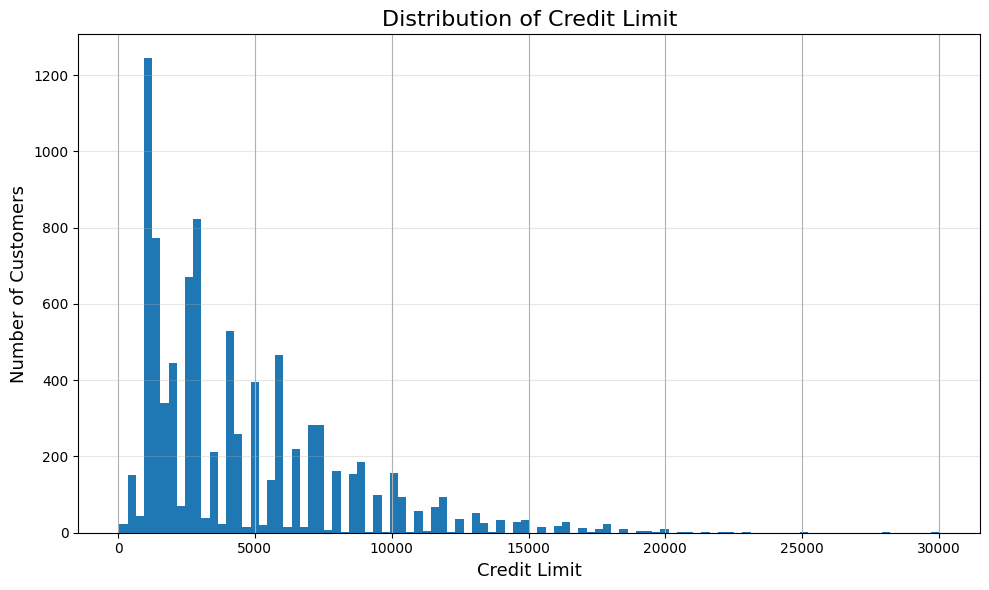

In [ ]:

plot_histogram(cc_explore,'CREDIT_LIMIT')

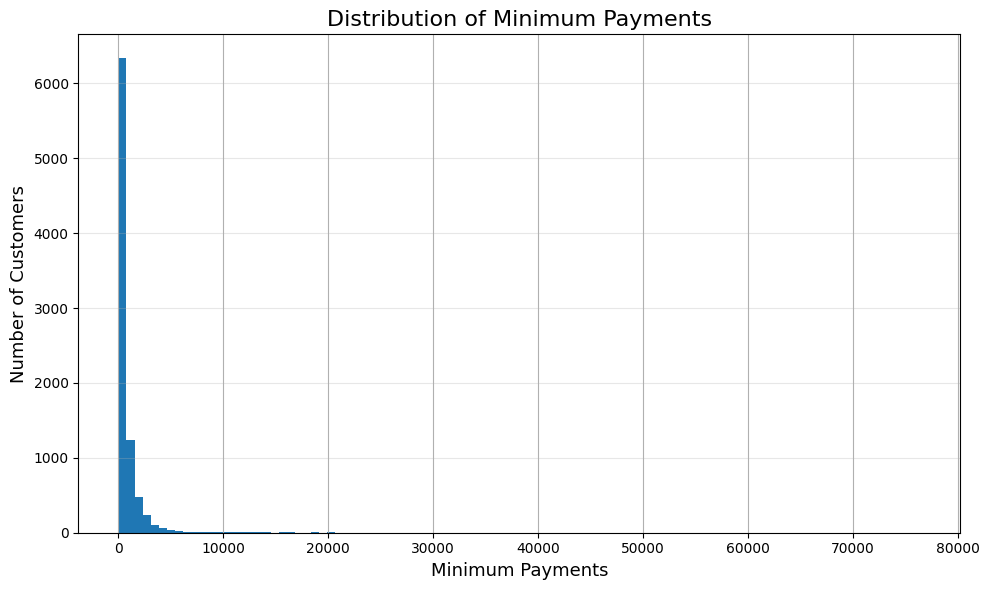

In [ ]:
plot_histogram(cc_explore,'MINIMUM_PAYMENTS')

check if log transofrming the data makes it better

---




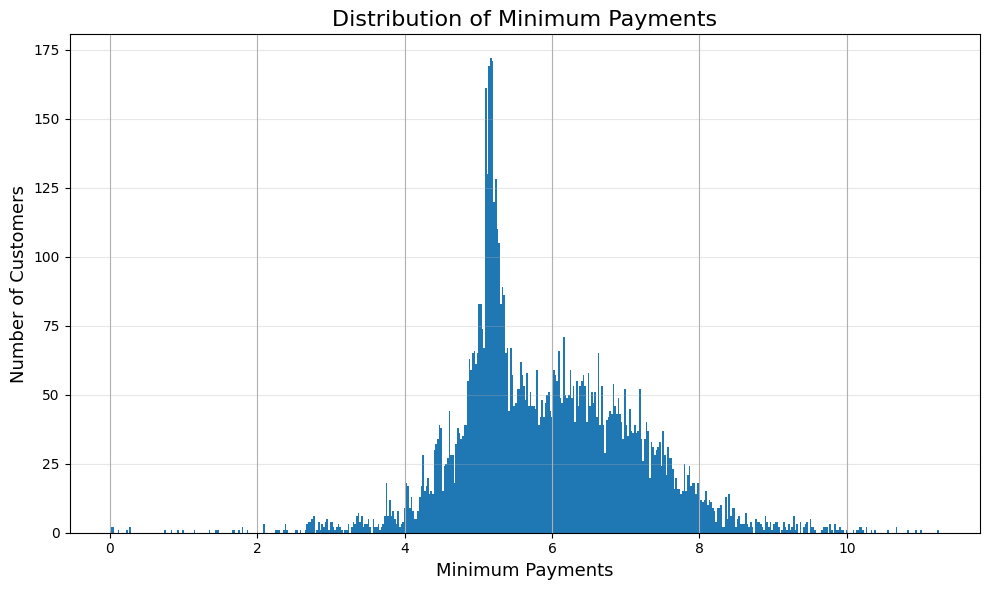

In [ ]:

import numpy as np

plt.figure(figsize=(10, 6))

np.log1p(cc_explore['MINIMUM_PAYMENTS']).hist(bins=500)

plt.title('Distribution of Minimum Payments', fontsize=16)
plt.xlabel('Minimum Payments', fontsize=13)
plt.ylabel('Number of Customers', fontsize=13)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:


credit_limit_median=cc_explore['CREDIT_LIMIT'].median()
min_payments_median=cc_explore['MINIMUM_PAYMENTS'].median()
cc_explore['CREDIT_LIMIT']=cc_explore['CREDIT_LIMIT'].fillna(credit_limit_median)
cc_explore['MINIMUM_PAYMENTS']=cc_explore['MINIMUM_PAYMENTS'].fillna(min_payments_median)


we see that many columns have zero as thier first quaritle and some even have zero as thier median

In [ ]:
cc_explore.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.282473,1733.143852,844.906767,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.646702,2895.063757,2332.792322,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,170.857654,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,788.713501,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


many of the features are right tailed

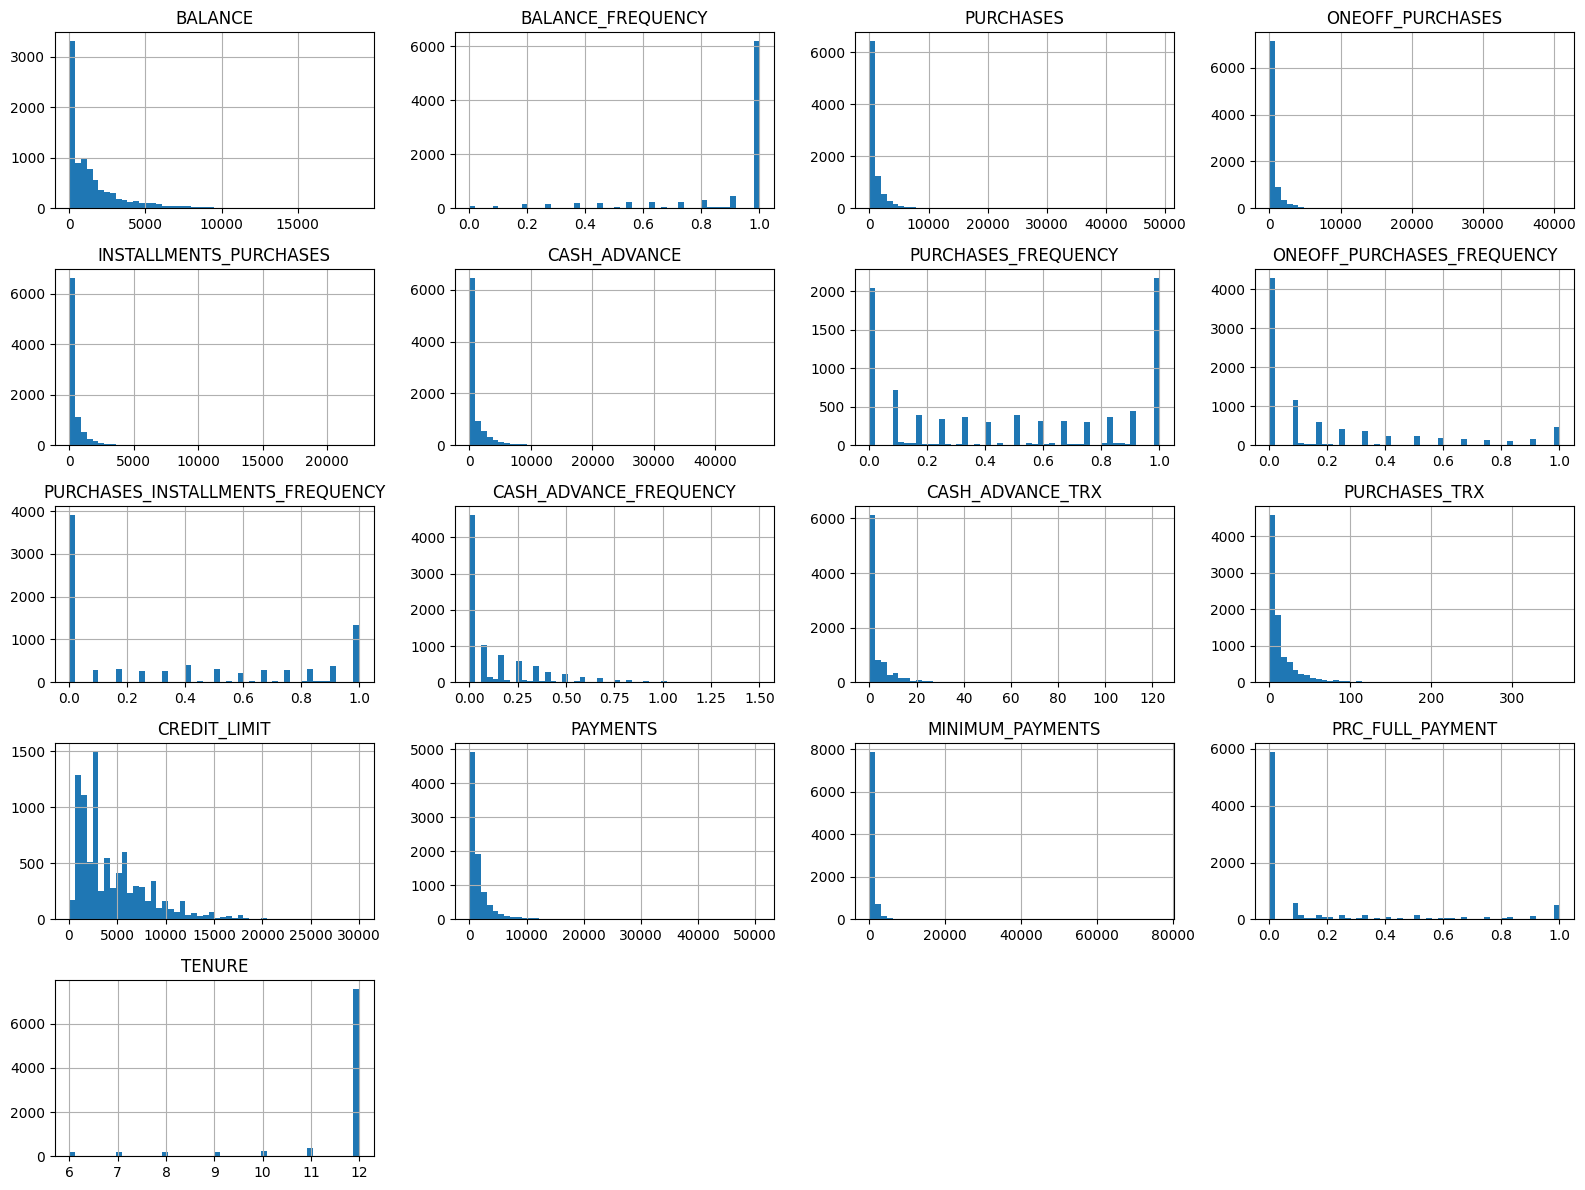

In [ ]:
import matplotlib.pyplot as plt

cc_explore.hist(
    bins=50,
    figsize=(16, 12)
)

plt.tight_layout()
plt.show()

checking if log makes things better

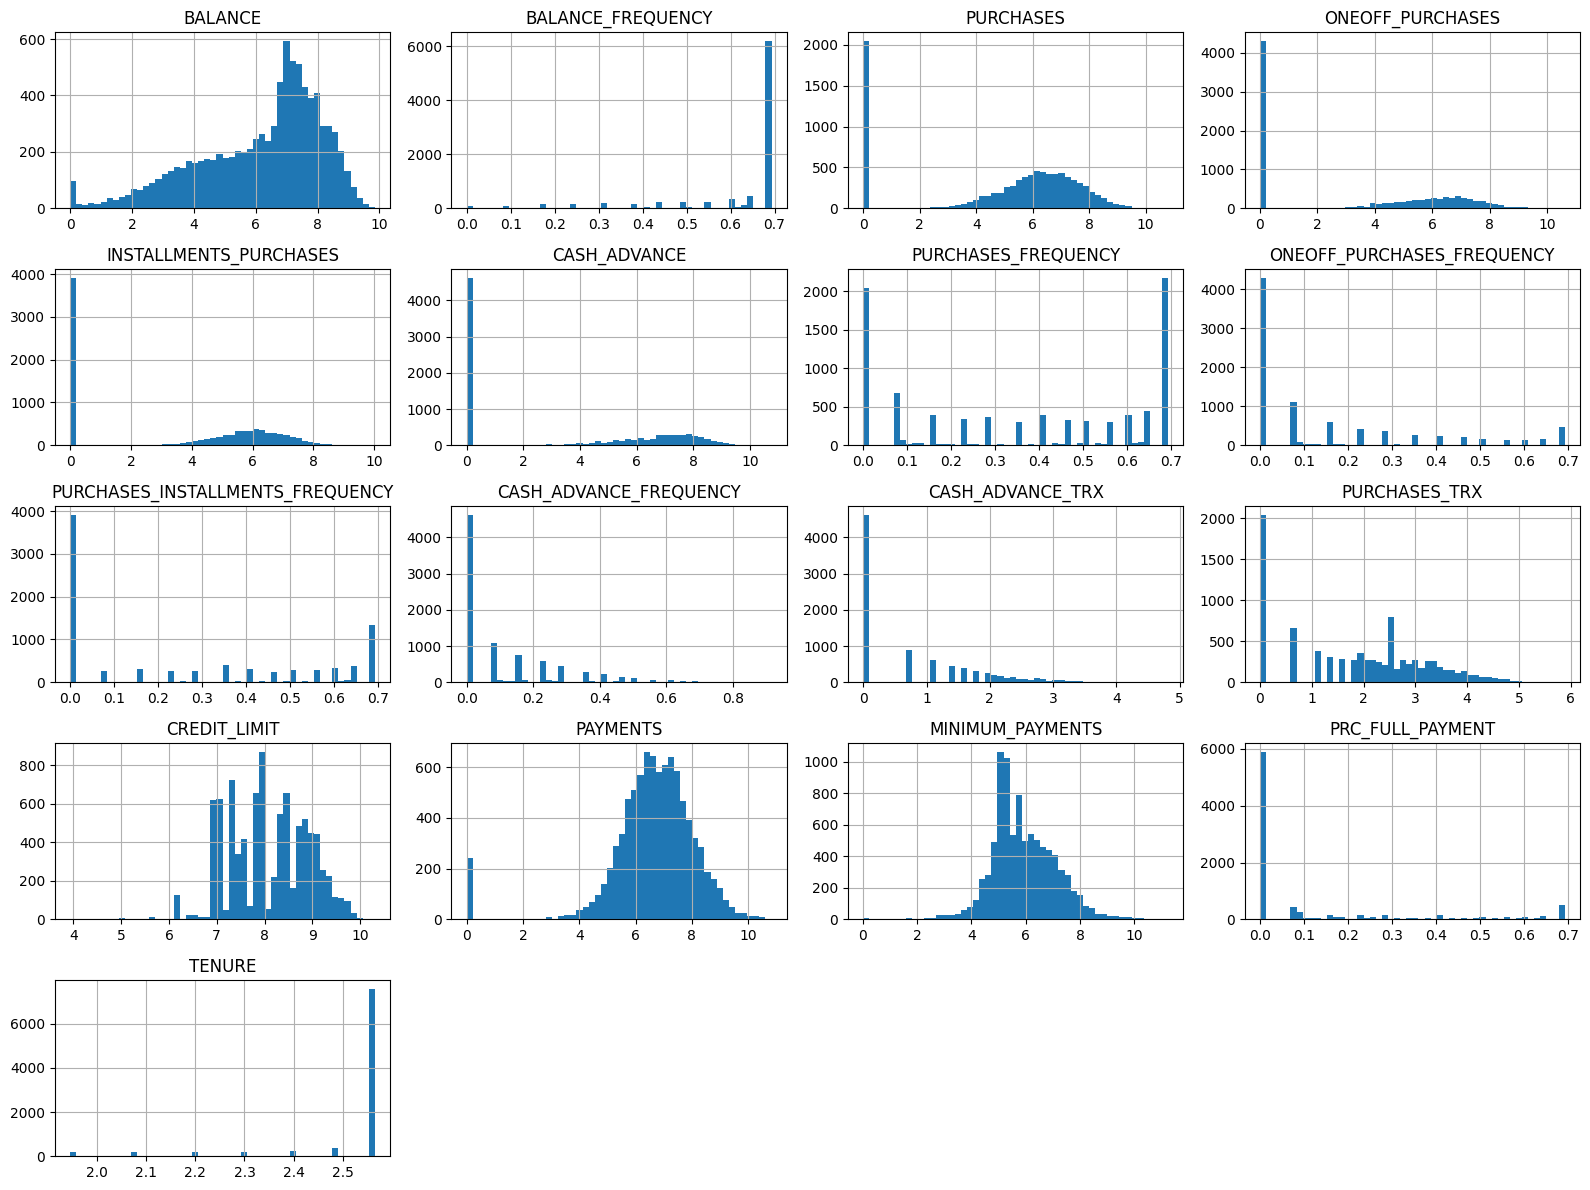

In [ ]:
import matplotlib.pyplot as plt

np.log1p(cc_explore).hist(
    bins=50,
    figsize=(16, 12)
)

plt.tight_layout()
plt.show()

most of the customers have been a credit card holder for 12 months

In [ ]:
cc_explore['TENURE'].value_counts(normalize=True)

,proportion
TENURE,
12,0.847374
11,0.040782
10,0.026369
6,0.022793
8,0.021899
7,0.021229
9,0.019553


## PURCHASES and CASH_ADVANCE

The origin of zeros in these columns and thier related columns (ONEOFF_PURCHASES,INSTALLMENT_PURCHASES,CASH_ADVANCE_TRX, PURCHASES_TRX)
can be understood by the following facts:
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.

These facts account for large number of zeros in CASH_ADVANCE and PURCHASES.
INSTALLMENT_PURCHASES and ONEOFF_PURCHASES bear the burden of zeros from the previous facts plus the fact that Of those who make purchases (77% of people) 27% only do one off and 32% only do installments

The zeros in CASH_ADVANCE and PURCHASES almost account for zeros in CASH_ADVANCE_TRX and PURCHASES_TRX

Similarly the zeros in many of the frequencies may also be due to this



The most frequent number of transactions is 1. In purchase_trx it is closely followed by 12

In [ ]:
cc_explore['CASH_ADVANCE'].value_counts(normalize=True)

,proportion
CASH_ADVANCE,
0.000000,0.517095
197.915586,0.000112
1430.485333,0.000112
211.485981,0.000112
364.489187,0.000112
...,...
101.183886,0.000112
496.939698,0.000112
1204.068667,0.000112


In [ ]:
purchase_cash=cc_explore.copy()
purchase_cash['taken_cash']=purchase_cash['CASH_ADVANCE']>0
purchase_cash['made_purchase']=purchase_cash['PURCHASES']>0
pd.crosstab(purchase_cash['made_purchase'],purchase_cash['taken_cash'],normalize='all')

taken_cash,False,True
made_purchase,,
False,0.000112,0.228268
True,0.516983,0.254637


In [ ]:
purchases=cc_explore[cc_explore['PURCHASES']>0].copy()
purchases['made_installments']=purchases['INSTALLMENTS_PURCHASES']>0
purchases['made_oneoff_purchases']=purchases['ONEOFF_PURCHASES']>0
print(pd.crosstab(purchases['made_installments'],purchases['made_oneoff_purchases'],normalize='all'))
print(len(purchases)/len(cc_explore))



made_oneoff_purchases     False     True 
made_installments                        
False                  0.000000  0.271358
True                   0.326962  0.401680
0.7716201117318435


In [ ]:
(cc_explore['PURCHASES_TRX'].astype(bool) ^ cc_explore['PURCHASES'].astype(bool)).sum()

np.int64(6)

In [ ]:
(cc_explore['CASH_ADVANCE_TRX'].astype(bool) ^ cc_explore['CASH_ADVANCE'].astype(bool)).sum()

np.int64(0)

In [ ]:
cc_explore[cc_explore['PURCHASES_TRX']>0]['PURCHASES_TRX'].value_counts(normalize=True)

,proportion
PURCHASES_TRX,
1,0.096583
12,0.082537
2,0.054880
6,0.050970
3,0.045468
...,...
309,0.000145
224,0.000145
133,0.000145


## Credit card usage
69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers


In [ ]:
cc_explore['BALANCE_FREQUENCY'].value_counts(normalize=True)

,proportion
BALANCE_FREQUENCY,
1.000000,0.693966
0.909091,0.045810
0.818182,0.031061
0.727273,0.024916
0.545455,0.024469
0.636364,0.023352
0.454545,0.019218
0.363636,0.018994
0.272727,0.016872


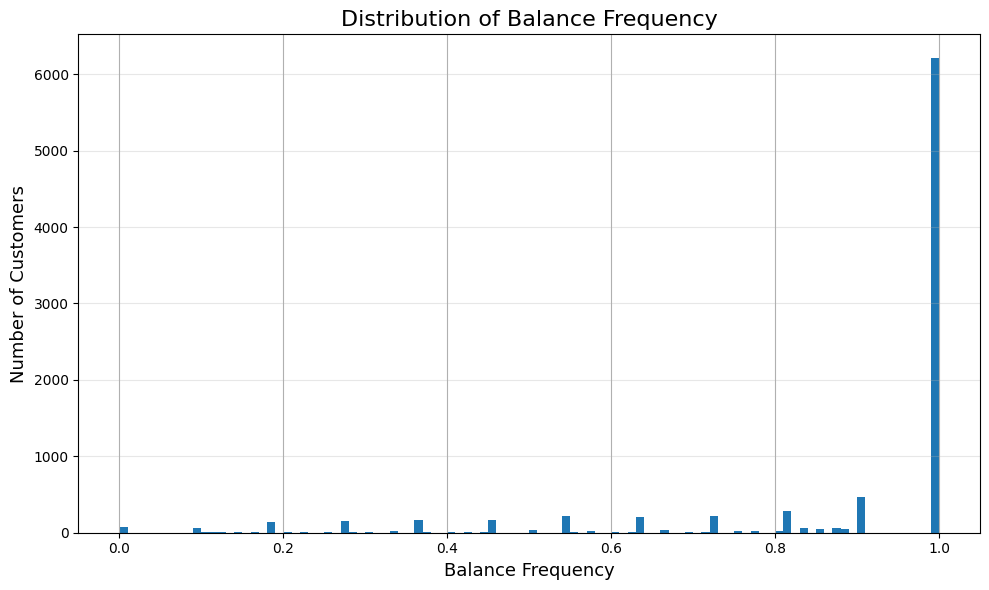

In [ ]:
plot_histogram(cc_explore,'BALANCE_FREQUENCY')

## more than 65% of people do not pay full payment ever

In [ ]:
(cc_explore['PAYMENTS']==0).sum()

np.int64(240)

In [ ]:
cc_explore['PRC_FULL_PAYMENT'].value_counts(normalize=True)

,proportion
PRC_FULL_PAYMENT,
0.000000,0.659553
1.000000,0.054525
0.083333,0.047598
0.166667,0.018547
0.250000,0.017430
0.500000,0.017430
0.090909,0.017095
0.333333,0.014972
0.100000,0.010503


1. With PURCHASES going up ONEOFF_PURCHASES go up reliably (0.92) and rougly 70% of the increase in purchases is due to ONEOFF_PURCHASES. THe customers consistently make ONEOFF_PURCHASES


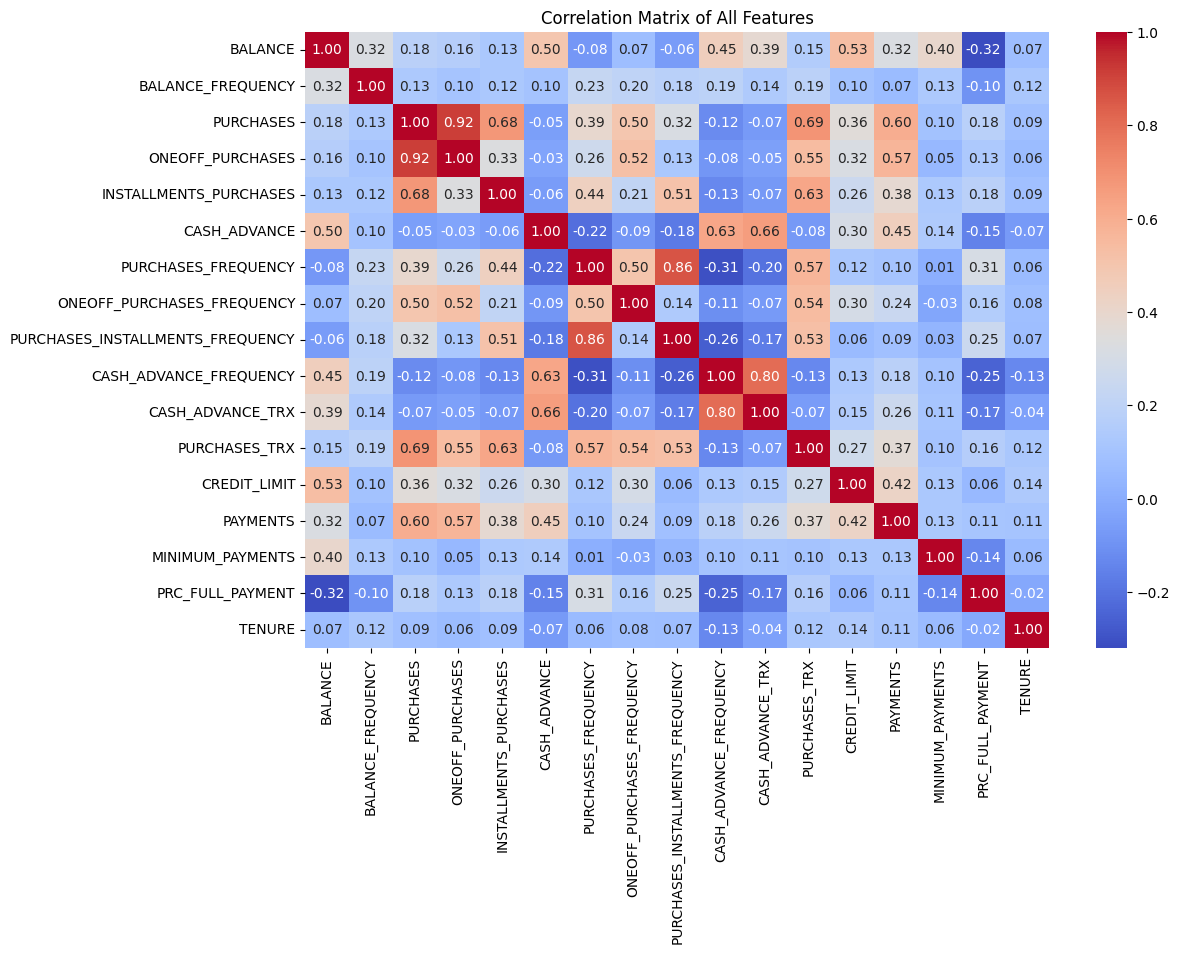

In [ ]:
import seaborn as sns
all_correlations=cc_explore.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(all_correlations, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of All Features')
plt.show()


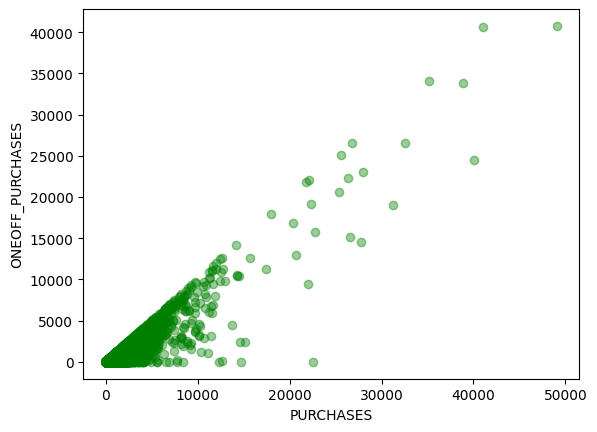

In [ ]:
plt.scatter(x=cc_explore['PURCHASES'],y=cc_explore['ONEOFF_PURCHASES'],c='g',alpha=0.4)
plt.xlabel('PURCHASES')
plt.ylabel('ONEOFF_PURCHASES')
plt.show()

In [ ]:
m,b=np.polyfit(cc_explore['PURCHASES'],cc_explore['ONEOFF_PURCHASES'],1)
print(f' m:{m}')
print(f' b:{b}')


 m:0.7122692273341492
 b:-122.1145606791352


##PCA plotting (before running kmeans)
1. The functions plot_kmeans_clusters_2d and its 3D version is used to plot pca version of the high dimensional space in which kmeans operates(after the log transformation and standard scaling)
2. First, original data(after log transform and standard scaling) is plotted using pca before running any kmean to recognize cluster ourselves.
3. Then the same thing is repeated with the enhanced dataset

In [ ]:
from sklearn.base import clone
from matplotlib.colors import BoundaryNorm

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'b.',alpha=0.3, markersize=1)


def plot_kmeans_clusters_2d(data,labels, centroids, ):


    pca=PCA(n_components=2)
    X=pca.fit_transform(data)
    centroids_2d=pca.transform(centroids)
    # Plotting
    plt.figure(figsize=(10, 8))
    norm = BoundaryNorm(
    range(11),
    ncolors=10
    )

    plt.scatter(X[:,0],X[:,1],c=labels, cmap='tab10',norm=norm,
                        s=10, alpha=0.4, edgecolors='none',marker='o')


    # Plot centroids
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
                marker='o', s=35, linewidths=8,
                c=list(range(len(centroids))), cmap='tab10',norm=norm, zorder=10, alpha=0.9)
    plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1],
                marker='x', s=2, linewidths=12,
                color='red', zorder=11, alpha=1)


    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:


from matplotlib.animation import FuncAnimation
from sklearn.decomposition import PCA


plt.rcParams['animation.embed_limit'] = 200  # MB, so jshtml doesn't get truncated


def anim_kmeans_clusters_3d(data,labels=None,centroids=None):
    pca=PCA(n_components=3)
    transformed_data_3d=pca.fit_transform(data)
    if centroids is not None:
      centroids_3d=pca.transform(centroids)
    fig = plt.figure(figsize=(15, 12))
    ax = fig.add_subplot(111, projection='3d')

    x, y, z = transformed_data_3d[:, 0], transformed_data_3d[:, 1], transformed_data_3d[:, 2]
    norm = BoundaryNorm(
    range(11),
    ncolors=10
    )


    if labels is not None:
        sc = ax.scatter(x, y, z, c=labels, cmap='tab10',
                        s=30, alpha=0.3, edgecolors='none',norm=norm, depthshade=True,marker='s')
    else:
        sc = ax.scatter(x, y, z, s=30, alpha=0.3, edgecolors='none',color='green', depthshade=True)
    if centroids is not None:
      cmap=plt.get_cmap('tab10')
      sc = ax.scatter(
          centroids[:, 0],
          centroids[:, 1],
          centroids[:, 2],
          marker='o',
          s=250,
          facecolors='none',
          edgecolors=cmap(range(len(centroids))),
          linewidths=3,
          alpha=1
      )

      # X markers
      sc=ax.scatter(
          centroids[:, 0],
          centroids[:, 1],
          centroids[:, 2],
          marker='x',
          s=200,
          color='red',
          linewidths=5,
          zorder=11
      )

    # ---- labels & title ----
    ax.set_xlabel('Principal Component 1', labelpad=12, fontsize=11)
    ax.set_ylabel('Principal Component 2', labelpad=12, fontsize=11)
    ax.set_zlabel('Principal Component 3', labelpad=12, fontsize=11)
    ax.set_title('3D PCA of Credit Card Data', fontsize=16, pad=20, fontweight='bold')

    # ---- remove the grid entirely ----
    ax.grid(False)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_visible(False)      # remove background panes
        axis._axinfo['grid']['linewidth'] = 0  # kill grid lines
    ax.set_axis_off()
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=25, azim=45)






    # ---- full 360° rotation ----
    def rotate(angle):
        ax.view_init(elev=25, azim=angle)
        return (sc,)

    anim = FuncAnimation(
        fig, rotate,
        frames=np.arange(0, 360, 2),
        interval=40, blit=False, repeat=True
    )

    plt.close(fig)
    return anim




In [ ]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline,Pipeline
preprocessor=make_pipeline(
     FunctionTransformer(func=np.log1p,inverse_func=np.expm1),
    StandardScaler(),
)

In [ ]:
import matplotlib
matplotlib.rc('animation', html='jshtml')



There seem to be atleast two clusters that stand out but we must be cautious in our conslusion because the first three pca components only explain 64% of the variance

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from IPython.display import HTML


animation=anim_kmeans_clusters_3d(preprocessor.fit_transform(cc_explore))
HTML(animation.to_jshtml())

In [ ]:
pca_pipeline=Pipeline([
    ('preprocessing',preprocessor),
    ('pca',PCA(n_components=3))
]
)
pca_pipeline.fit(cc_explore)
print(f'explained variance ratio for the three dimensions: {pca_pipeline[-1].explained_variance_ratio_}')
print(f'total explained varaince ratio :{pca_pipeline[-1].explained_variance_ratio_.sum()}')

explained variance ratio for the three dimensions: [0.34455343 0.22005376 0.09455136]
total explained varaince ratio :0.6591585465446822


1. In this section I try to enhance the data set by adding new features and see if by adding them we can gather substantially more signal in our first three componets so that our visutalization is closer to the kmeans' operating space
but the results are not encouraging

2. After creating the new features we check if the new columns are correlated with each other so as to reduce redundancy because correlated columns affect kmeans badly

In [ ]:
enhanced_cc=cc_explore.copy()
(enhanced_cc['CREDIT_LIMIT']==0).sum()
(enhanced_cc['MINIMUM_PAYMENTS']==0).sum()


np.int64(0)

Correlation Matrix of New Features:
                    credit_util  cash_reliance  payment_to_min  \
credit_util            1.000000       0.405861       -0.054649   
cash_reliance          0.405861       1.000000       -0.009876   
payment_to_min        -0.054649      -0.009876        1.000000   
avg_purchase_value    -0.073782      -0.211207        0.001926   
total_trx              0.025143      -0.187829        0.008880   

                    avg_purchase_value  total_trx  
credit_util                  -0.073782   0.025143  
cash_reliance                -0.211207  -0.187829  
payment_to_min                0.001926   0.008880  
avg_purchase_value            1.000000  -0.040980  
total_trx                    -0.040980   1.000000  


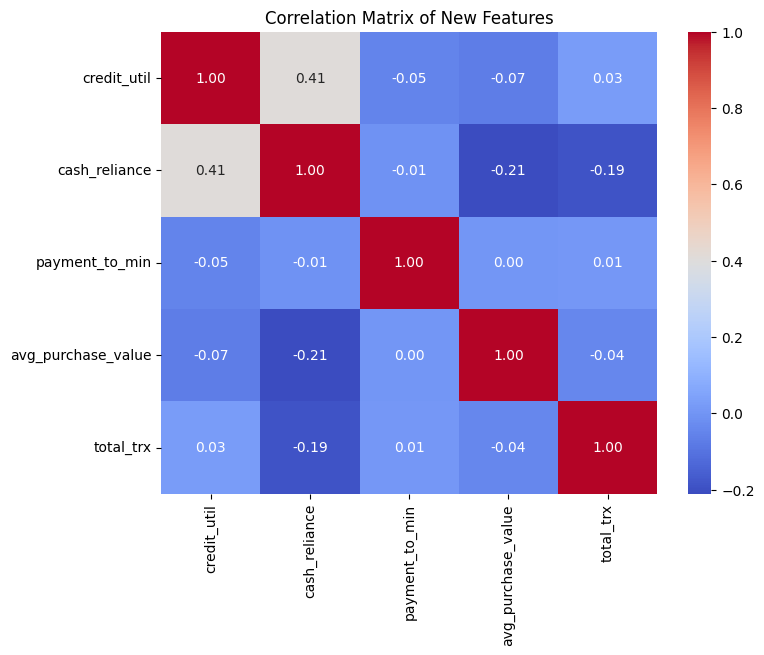

In [ ]:


enhanced_cc['credit_util'] = enhanced_cc['BALANCE'] / enhanced_cc['CREDIT_LIMIT']
enhanced_cc['cash_reliance'] = (enhanced_cc['CASH_ADVANCE'] / (enhanced_cc['PURCHASES'] + enhanced_cc['CASH_ADVANCE'])).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['payment_to_min'] = (enhanced_cc['PAYMENTS'] / enhanced_cc['MINIMUM_PAYMENTS']).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['avg_purchase_value'] = (enhanced_cc['PURCHASES'] / enhanced_cc['PURCHASES_TRX']).replace([-np.inf,np.inf],np.nan).fillna(0)
enhanced_cc['total_trx'] = enhanced_cc['PURCHASES_TRX'] + enhanced_cc['CASH_ADVANCE_TRX']


# Select only the newly created columns for correlation calculation
new_features_corr = enhanced_cc[['credit_util', 'cash_reliance', 'payment_to_min', 'avg_purchase_value', 'total_trx']].corr()

print("Correlation Matrix of New Features:")
print(new_features_corr)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(new_features_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of New Features')
plt.show()

In [ ]:
pca_pipeline.fit(enhanced_cc)
print(f'explained variance ratio for the three dimensions: {pca_pipeline[-1].explained_variance_ratio_}')
print(f'total explained varaince ratio :{pca_pipeline[-1].explained_variance_ratio_.sum()}')

explained variance ratio for the three dimensions: [0.35333217 0.20785697 0.09342047]
total explained varaince ratio :0.6546096026682733


3d animation of the shape of the processed enhanced data

In [ ]:
enhanced_animation=anim_kmeans_clusters_3d(preprocessor.fit_transform(enhanced_cc))
HTML(enhanced_animation.to_jshtml())


##Trying kmeans

1. We run kmean with an arbitrary number of clusters(4) on the unenhanced  dataset
2. We determine the optimal number of clusters (2) using sihoulette score
3. we rerun the kmean pipeline with 2 clusters on the unenhanced dataset and visualize it
4. Then we do the same thing again with enhanced dataset, results are more encouraging.

In [ ]:
from sklearn.cluster import KMeans


kmean_pipeline=Pipeline(
    [
        ('preprocessing',preprocessor),
        ('kmean',KMeans(n_clusters=4,n_init=10,random_state=42))
    ]
)
kmean_pipeline.fit(cc_explore)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=4, n_init=10, random_state=42))])

/tmp/ipykernel_1168/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


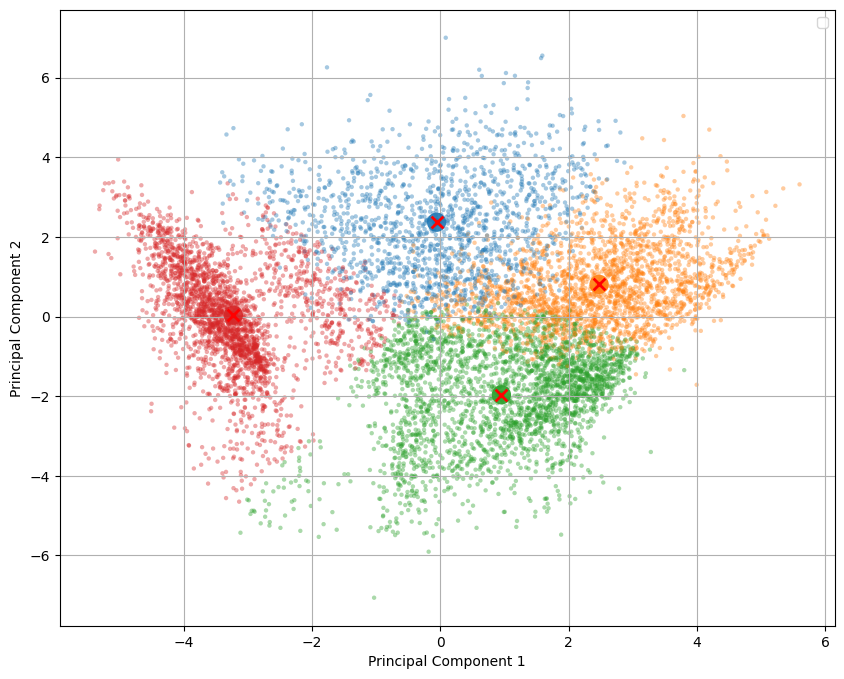

In [ ]:

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

2 seems to be the best value for k confirming our pca visualization from before

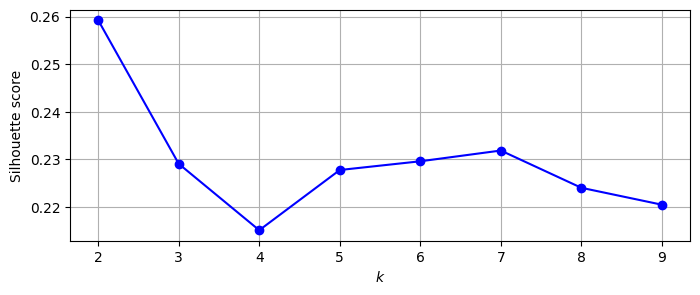

In [ ]:
from sklearn.metrics import silhouette_score
transformed_data=preprocessor.fit_transform(cc_explore)
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(transformed_data)
                for k in range(1, 10)]
silhouette_scores = [silhouette_score(transformed_data, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")

plt.grid()

plt.show()

##visualizaing the two clusters(the unenhanced data version)
**important_point**: I will refer to the clusters as *concentrated* cluster and *diffused* cluster. We cannot use color as our guide because when we rerun the kmean on enhanced data the actual same cluster is assigned different color(because kmean doesnt 'know' the clusters across runs on different data)

1. From what we see from two dimensions it looks like the concentrated  cluster has assimilated a part that should belong to diffused cluster but from three dimension visualization it becomes clear that not only concentrated cluster should assimilate the mentioned part but also extend to another part of the diffused cluster

In [ ]:
kmean_pipeline.set_params(kmean__n_clusters=2)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=2, n_init=10, random_state=42))])

/tmp/ipykernel_1168/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


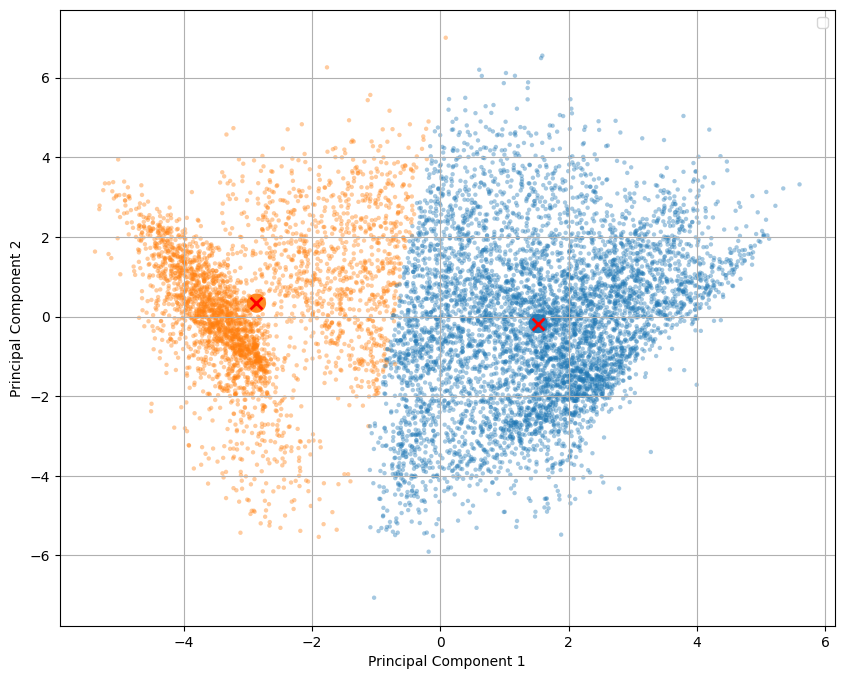

In [ ]:
kmean_pipeline.fit(cc_explore)

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

In [ ]:
animation=anim_kmeans_clusters_3d(kmean_pipeline[:-1].transform(cc_explore),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)
HTML(animation.to_jshtml())

## Trying with enhanced dataset
now in the 3d plot the light blue cluster takes over the previous blue part that seemed like it should belong to the light blue cluster

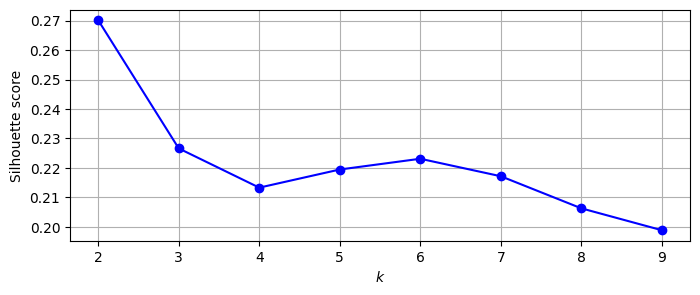

In [ ]:
from sklearn.metrics import silhouette_score
transformed_data=preprocessor.fit_transform(enhanced_cc)
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(transformed_data)
                for k in range(1, 10)]
silhouette_scores = [silhouette_score(transformed_data, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")

plt.grid()

plt.show()

In [ ]:
kmean_pipeline.set_params(kmean__n_clusters=2)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('functiontransformer',
                                  FunctionTransformer(func=<ufunc 'log1p'>,
                                                      inverse_func=<ufunc 'expm1'>)),
                                 ('standardscaler', StandardScaler())])),
                ('kmean', KMeans(n_clusters=2, n_init=10, random_state=42))])

/tmp/ipykernel_1168/1469479085.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


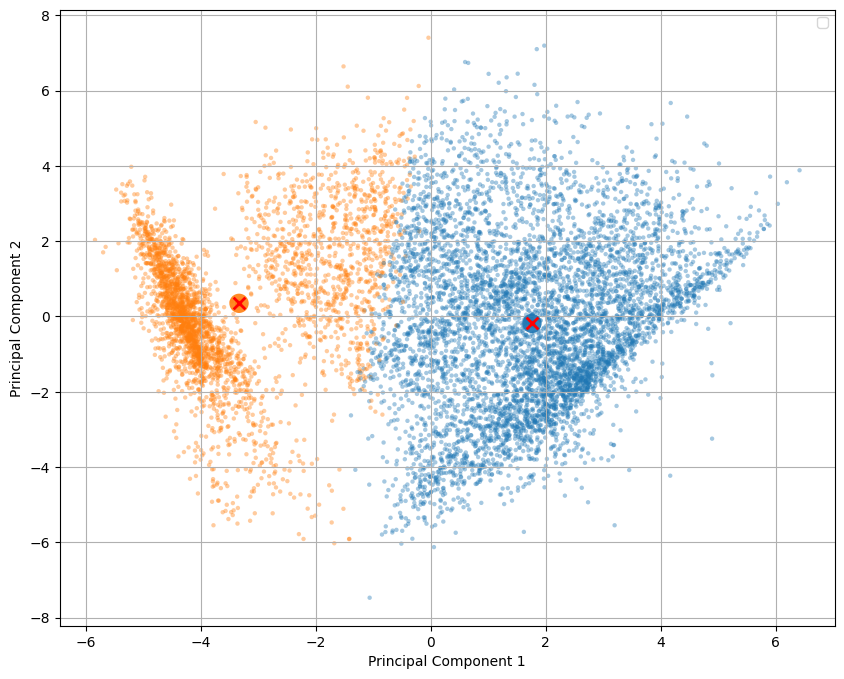

In [ ]:
kmean_pipeline.fit(enhanced_cc)

plot_kmeans_clusters_2d(kmean_pipeline[:-1].transform(enhanced_cc),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)

In [ ]:
animation=anim_kmeans_clusters_3d(kmean_pipeline[:-1].transform(enhanced_cc),kmean_pipeline[-1].labels_,kmean_pipeline[-1].cluster_centers_)
HTML(animation.to_jshtml())

#Week 5

## Updation of week 4: Interpreting the clusters and visualization of segments,their characteristics and differences
1. We display numerical information of the columns of each group in two parts(because there are a large number of columns)

In [ ]:
cc_evaluate=enhanced_cc.copy()
labels=kmean_pipeline[-1].labels_
cc_evaluate['cluster']=labels
centers_scaled=kmean_pipeline[-1].cluster_centers_
centers=kmean_pipeline[0].inverse_transform(centers_scaled)



adding a new col

In [ ]:
cc_evaluate['payment_balance'] = cc_evaluate['PAYMENTS'] / cc_evaluate['BALANCE'].replace(0, np.nan)

# rows where BALANCE==0 but PAYMENTS>0 => paid off everything => healthiest => cap-high
# rows where BALANCE==0 AND PAYMENTS==0 => inactive => should be 0 (paid nothing, owe nothing)
paid_off = (cc_evaluate['BALANCE'] == 0) & (cc_evaluate['PAYMENTS'] > 0)
inactive = (cc_evaluate['BALANCE'] == 0) & (cc_evaluate['PAYMENTS'] == 0)

cap = cc_evaluate['payment_balance'].quantile(0.99)          # the high-end cap
cc_evaluate.loc[paid_off, 'payment_balance'] = cap            # treat "paid off" as top of range
cc_evaluate.loc[inactive, 'payment_balance'] = 0

In [ ]:
cc_evaluate['avg_transact_value']=(cc_evaluate['PURCHASES']+cc_evaluate['CASH_ADVANCE'])/cc_evaluate['total_trx']
cc_evaluate['avg_purchase_value'].fillna(0)


,avg_purchase_value
0,47.700000
1,0.000000
2,64.430833
3,1499.000000
4,16.000000
...,...
8945,48.520000
8946,50.000000
8947,28.880000
8948,0.000000


In [ ]:
cc_evaluate['oneoff_tendency']=cc_evaluate['ONEOFF_PURCHASES']/(cc_evaluate['ONEOFF_PURCHASES']+cc_evaluate['INSTALLMENTS_PURCHASES'])

In [ ]:
groups=[]
for name ,group in cc_evaluate.groupby('cluster'):
  groups.append(group)


displaying half columns of each group, because otherwise the middle ones are skipped from displaying

In [ ]:
half=cc_evaluate.shape[1]//2
half

13

In [ ]:
groups[0].iloc[:,:half].describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT
count,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000
mean,1116.089817,0.862809,1465.399795,855.371083,610.415695,327.923817,0.694112,0.282236,0.529648,0.048743,1.115608,21.513832,4581.430485
std,1785.789252,0.249945,2495.508918,1972.725913,1060.716408,1256.364056,0.320677,0.331442,0.384951,0.122490,3.683757,28.281333,3738.579720
min,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,0.000000,150.000000
25%,62.055935,0.818182,305.787500,0.000000,59.112500,0.000000,0.416667,0.000000,0.111111,0.000000,0.000000,6.000000,1600.000000
50%,384.384555,1.000000,734.240000,229.010000,300.000000,0.000000,0.833333,0.166667,0.583333,0.000000,0.000000,12.000000,3350.000000
75%,1390.780478,1.000000,1696.720000,992.910000,745.120000,0.000000,1.000000,0.500000,0.916667,0.000000,0.000000,26.000000,6500.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,29282.109150,1.000000,1.000000,1.000000,1.000000,62.000000,358.000000,30000.000000


In [ ]:
groups[1].iloc[:,:half].describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT
count,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000
mean,2413.131137,0.904642,128.410491,94.783908,33.762479,2210.916155,0.104692,0.051461,0.051745,0.298676,7.286361,1.831933,4329.337819
std,2323.390547,0.207310,499.900693,475.671233,136.925572,2723.303409,0.209896,0.121277,0.164436,0.215837,9.173196,4.490699,3436.113169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000
25%,875.909417,0.909091,0.000000,0.000000,0.000000,455.316185,0.000000,0.000000,0.000000,0.142857,2.000000,0.000000,1500.000000
50%,1624.327964,1.000000,0.000000,0.000000,0.000000,1378.023829,0.000000,0.000000,0.000000,0.250000,5.000000,0.000000,3000.000000
75%,3220.918224,1.000000,98.000000,25.245000,0.000000,2942.844887,0.083333,0.083333,0.000000,0.416667,9.000000,1.000000,6000.000000
max,16304.889250,1.000000,22101.780000,22101.780000,1945.950000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,77.000000,19600.000000


In [ ]:
groups[0].iloc[:,half:].describe()

,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,credit_util,cash_reliance,payment_to_min,avg_purchase_value,total_trx,cluster,payment_balance,avg_transact_value,oneoff_tendency
count,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.000000,5856.0,5856.000000,5856.000000,5856.000000
mean,1712.665397,709.214856,0.215082,11.625171,0.282098,0.089004,9.764293,95.384220,22.629440,0.0,47.564769,inf,0.454007
std,2921.697773,2233.347226,0.334696,1.193367,0.331654,0.205976,133.802957,181.937686,29.185575,0.0,1413.261276,NaN,0.412271
min,0.000000,0.019163,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.010000,0.000000
25%,374.004887,153.663018,0.000000,12.000000,0.019247,0.000000,1.087958,32.936667,7.000000,0.0,0.606484,35.247308,0.000000
50%,858.893876,211.194368,0.000000,12.000000,0.115123,0.000000,2.855036,55.286516,12.000000,0.0,3.126823,61.153595,0.429469
75%,1903.672000,583.881078,0.333333,12.000000,0.460773,0.000000,7.257573,92.594797,28.000000,0.0,10.201337,105.955320,0.907114
max,50721.483360,76406.207520,1.000000,12.000000,2.033580,0.974139,6840.528861,5981.666667,358.000000,0.0,79789.487199,inf,1.000000


In [ ]:
groups[1].iloc[:,half:].describe()


,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,credit_util,cash_reliance,payment_to_min,avg_purchase_value,total_trx,cluster,payment_balance,avg_transact_value,oneoff_tendency
count,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.000000,3094.0,3.094000e+03,3093.000000,1052.000000
mean,1771.903332,1101.730242,0.037564,11.313187,0.590996,0.929794,7.724570,33.152108,9.118293,1.0,4.691763e+02,inf,0.701558
std,2844.035693,2490.463067,0.121896,1.556514,0.410821,0.159453,80.724951,96.749099,11.210485,0.0,2.159688e+04,NaN,0.425227
min,0.000000,0.117036,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000e+00,0.010000,0.000000
25%,396.251598,301.441109,0.000000,12.000000,0.353045,0.937394,0.733315,0.000000,2.000000,1.0,2.410501e-01,101.766866,0.225017
50%,853.034494,538.303422,0.000000,12.000000,0.629976,1.000000,1.087226,0.000000,5.000000,1.0,3.676921e-01,223.723087,1.000000
75%,1899.244623,1149.144908,0.000000,12.000000,0.868200,1.000000,3.526558,34.596875,12.000000,1.0,1.439494e+00,440.692946,1.000000
max,39461.965800,61031.618600,1.000000,12.000000,15.909951,1.000000,2846.533661,1490.000000,144.000000,1.0,1.185884e+06,inf,1.000000


##**visualization of segments**

In [ ]:
HTML(animation.to_jshtml())



## The most dominant pattern CASH_ADVANCE

**Insight**
cluster 0 consumers use credit card for purchases transfering money directly to merchants(as the credit card is meant to be used ).Cluster 1 is smaller than Cluster 0. They take  cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently

**Evidence**
The cash_reliance variable offers the most drastic comparison. Since these distributions are right tailed. I have used violin plot and taken the log of distributions so that ranges are visible.Note that if a number is greater than another number after log transforming it is still greater. In all of the features cluster1 IQR goes past the cluster 0's IQR. As cash_reliance is calculated as a proprotion of purchase+cash_advance high cash_reliance automatically means low purchase reliance and vice versa. Statistcal test are also done


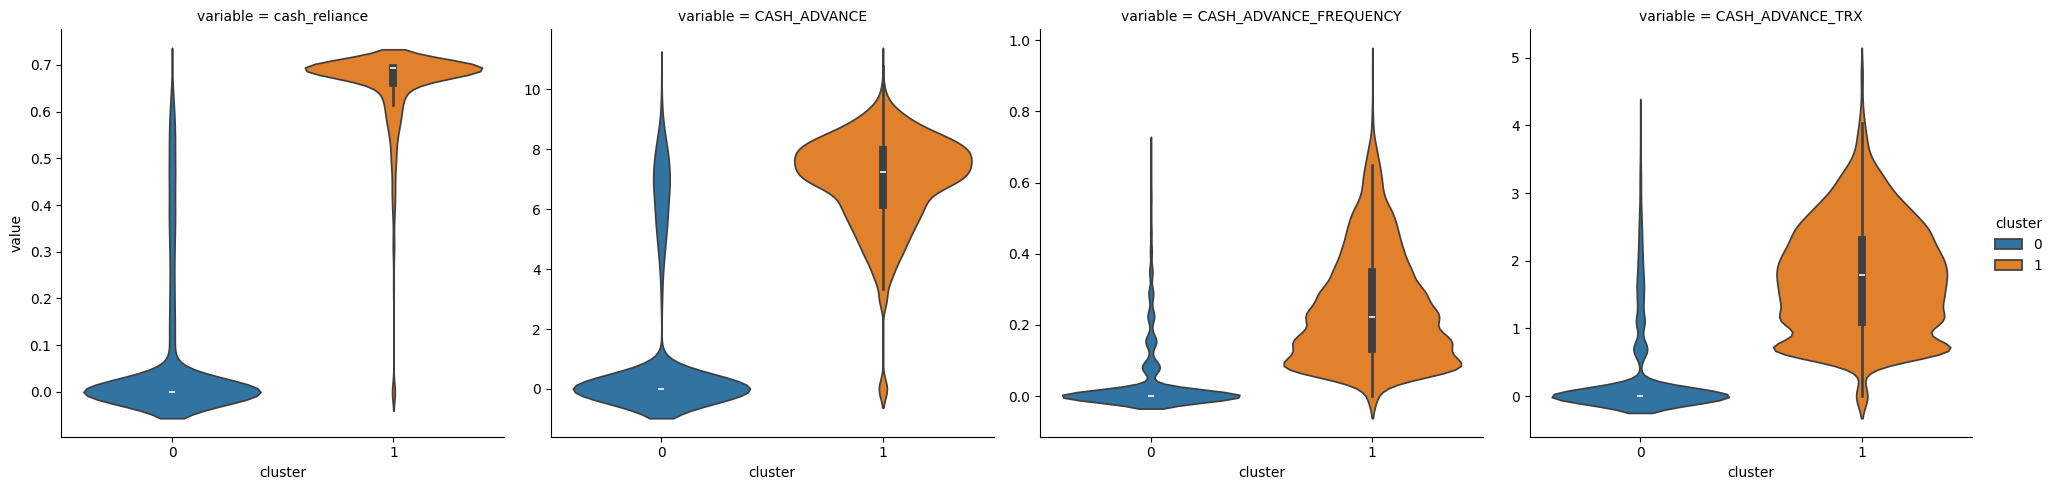

In [ ]:
import seaborn as sns
cash_cols=['cash_reliance','CASH_ADVANCE','CASH_ADVANCE_FREQUENCY','CASH_ADVANCE_TRX']
plot_cash_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=cash_cols,
    var_name='variable',
    value_name='value'
)
plot_cash_data['value']=np.log1p(plot_cash_data['value'])
sns.catplot(
    data=plot_cash_data,
    x='cluster',
    y='value',
    col='variable',
    kind='violin',
    hue='cluster',
    sharey=False
)


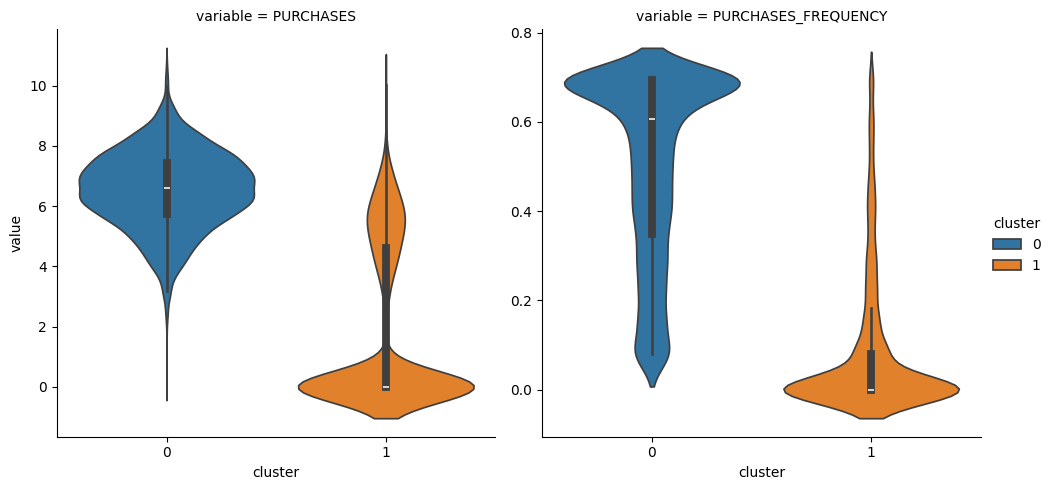

In [ ]:
import seaborn as sns
purchase_cols=['PURCHASES','PURCHASES_FREQUENCY']
plot_purchase_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=purchase_cols,
    var_name='variable',
    value_name='value'
)
plot_purchase_data['value']=np.log1p(plot_purchase_data['value'])
sns.catplot(
    data=plot_purchase_data,
    x='cluster',
    y='value',
    col='variable',
    kind='violin',
    hue='cluster',
    sharey=False
)

In [ ]:
from scipy.stats import mannwhitneyu
for col in cash_cols:
    stat, p = mannwhitneyu(groups[0][col], groups[1][col])
    print(f"{col:25s} p={p:.4g}")

cash_reliance             p=0
CASH_ADVANCE              p=0
CASH_ADVANCE_FREQUENCY    p=0
CASH_ADVANCE_TRX          p=0


In [ ]:
from scipy.stats import mannwhitneyu
for col in purchase_cols:
    stat, p = mannwhitneyu(groups[0][col], groups[1][col])
    print(f"{col:25s} p={p:.4g}")

PURCHASES                 p=0
PURCHASES_FREQUENCY       p=0


##Debt
**Insight**
cluster 0 customers have lower debt and have consumed lower proprtion of their credit limit. Cluster 1 customers are closer to their credit limit and have more debt to the bank

**evidence**

credit_limit of both clusters looks the same but when we look at balance(currently owed debt to the bank) and credit_util(proprotion of credit_lmit consumed) the medians of cluster1 are higher than the IQRs of clsuter 0

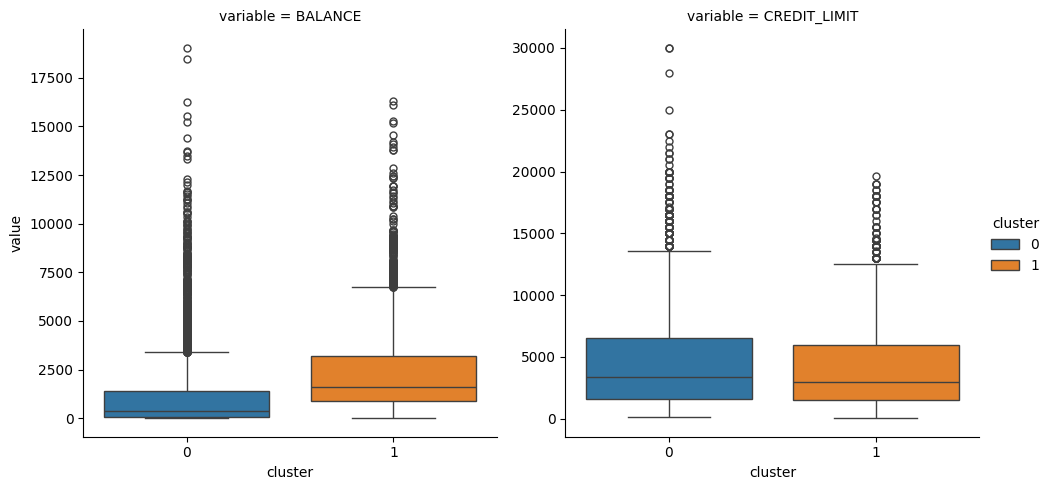

In [ ]:
debt_cols=['BALANCE','CREDIT_LIMIT']
plot_debt_data = cc_evaluate.melt(
    id_vars='cluster',
    value_vars=debt_cols,
    var_name='variable',
    value_name='value'
)

sns.catplot(
    data=plot_debt_data,
    x='cluster',
    y='value',
    col='variable',
    kind='box',
    hue='cluster',


    sharey=False
)

<Axes: xlabel='cluster', ylabel='credit_util'>

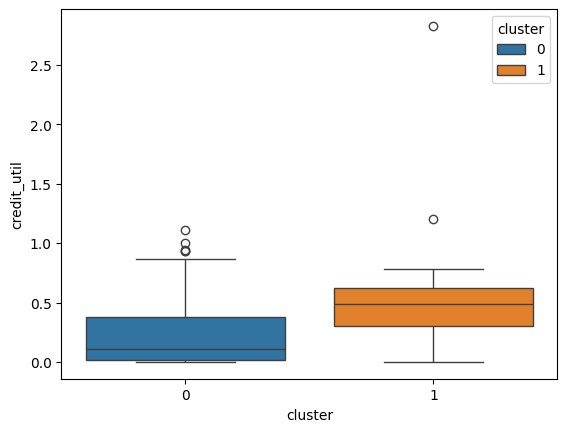

In [ ]:
sns.boxplot(
    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['credit_util']),
    hue=cc_evaluate['cluster']

)

##BALANCE_FREQUENCY show no difference
both groups inherit the pattern of the overall data set where a significant portion of the clientle are active to the highest degree and customers are thinly  spread among the remining degrees




It also looks like balnce_frequencies are unnaturally cut off at 1.

(0.0, 1.25)

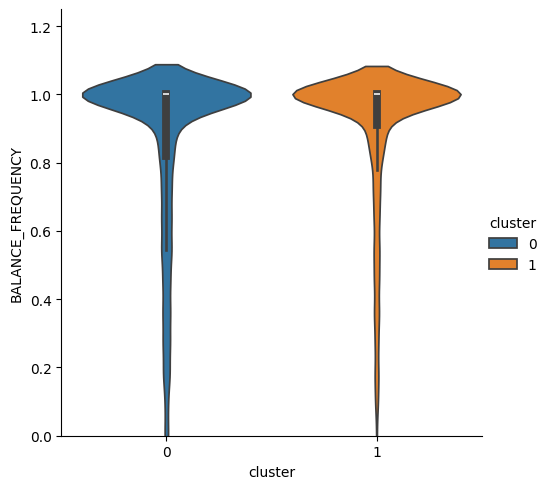

In [ ]:


sns.catplot(
    data=cc_evaluate,
    x='cluster',
    y='BALANCE_FREQUENCY',

    kind='violin',
    hue='cluster',
    sharey=False
)
plt.ylim(0,1.25)

In [ ]:
groups[0]['BALANCE_FREQUENCY'].value_counts(normalize=True)

,proportion
BALANCE_FREQUENCY,
1.000000,0.670936
0.909091,0.050717
0.818182,0.035690
0.545455,0.029713
0.636364,0.028859
0.727273,0.028689
0.454545,0.021687
0.363636,0.021516
0.272727,0.020833


##PAYMENT TO BALANCE Ratio
**Insight**
 cluster 0 have done more payment for one unit of debt they have. which is an indication that they have consistently paid their debts

On the other hand cluster 1 have smaller ratio, meaning less payment for one unit of debt which is associated with a higher-risk repayment profile (a statistical association across the group, not a judgement about any individual).
**Evidence**
If we look closely at the plot the median of cluster 1 is below the first quaritle of clsuter 0. Also we have performed a statistical test which confirms our finding



<Axes: xlabel='cluster', ylabel='payment_balance'>

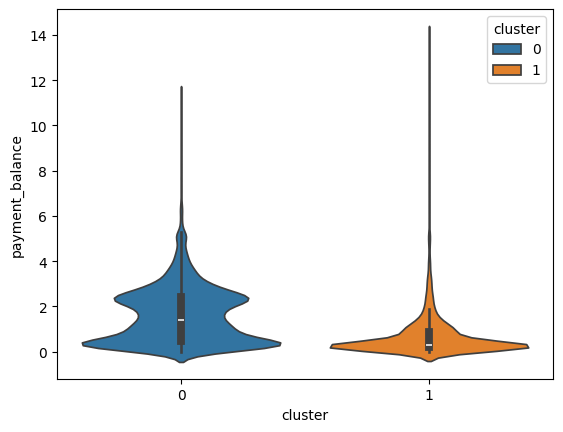

In [ ]:
sns.violinplot(

    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['payment_balance']),
    hue=cc_evaluate['cluster']
)


In [ ]:
_,p=mannwhitneyu(groups[0]['payment_balance'], groups[1]['payment_balance'])
print(f"payment_balance p={p:.4g}")

payment_balance p=0


##**cluster 1 takes cash out in larger amounts and and pays it back incrementally**
both clusters have the same balance_frequency but cluster 1 has less total_trx. on the other hand avg_transact_value is greater for cluster1. That is cluster1 customers  borrow money in larger amounts and in fewer number of transactions.Given that both clusters exhibit similar balance frequency, Cluster 1 customers would likely repay their larger cash advances over a greater number of installments, with each installment representing a smaller amount on average.

<Axes: xlabel='cluster', ylabel='total_trx'>

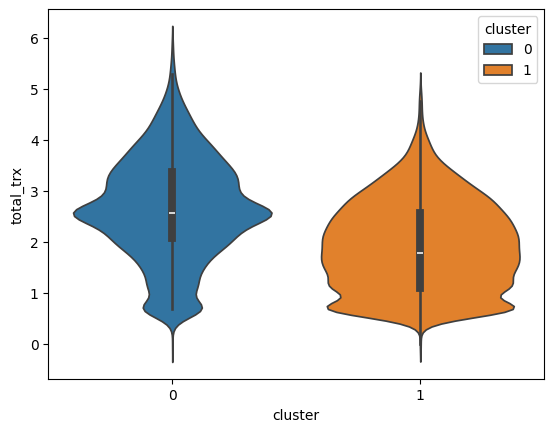

In [ ]:
sns.violinplot(

    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['total_trx']),
    hue=cc_evaluate['cluster']
)

<Axes: xlabel='cluster', ylabel='avg_transact_value'>

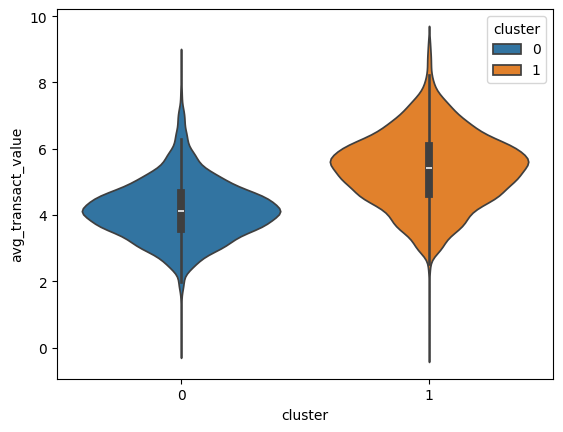

In [ ]:
sns.violinplot(

    x=cc_evaluate['cluster'],
    y=np.log1p(cc_evaluate['avg_transact_value']),
    hue=cc_evaluate['cluster']
)

 **installments vs one-off**: There seem to be quite a few hardliners in cluster 0 with installments hardliners being more common.

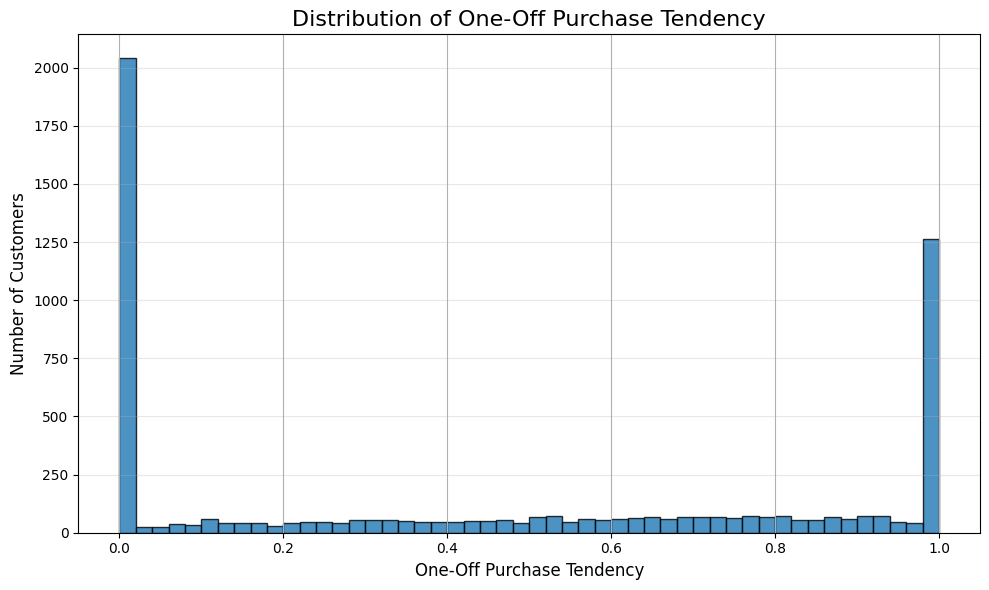

In [ ]:
plt.figure(figsize=(10, 6))

groups[0]['oneoff_tendency'].hist(
    bins=50,
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribution of One-Off Purchase Tendency', fontsize=16)
plt.xlabel('One-Off Purchase Tendency', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
oneoff_tendency=groups[0]['oneoff_tendency']
oneoff_tendency_conditions=[
    oneoff_tendency==0,
    (oneoff_tendency>0) & (oneoff_tendency<1),
    oneoff_tendency==1
]
oneoff_binned=pd.Series(np.select(oneoff_tendency_conditions,['zero','inbetween','one'],default='out_of_range'))

In [ ]:
oneoff_binned.value_counts(normalize=True)

,proportion
inbetween,0.445184
zero,0.345116
one,0.209699


##**Borrowing Frequency**
36% of cluster 0 is actively doing purchases to the highest frequency.
while a large bulk of cluster 1 are not drawing cash in advance much frequently.
In other words cluster 1 leads cluster 0 in borrwoing frequency.

Text(0.5, 1.0, 'PURCHASES_FREQUENCY')

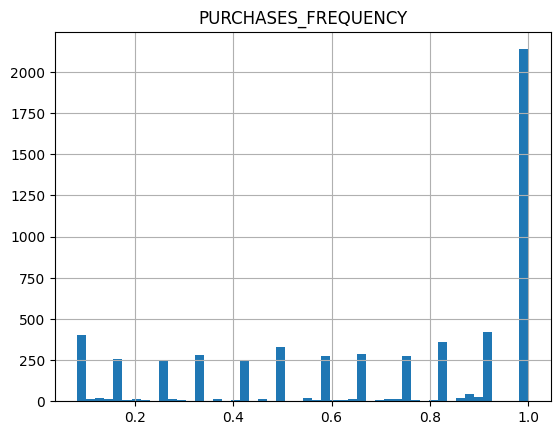

In [ ]:
groups[0]['PURCHASES_FREQUENCY'].hist(bins=50)
plt.title('PURCHASES_FREQUENCY')


In [ ]:
groups[0]['PURCHASES_FREQUENCY'].value_counts(normalize=True)

,proportion
PURCHASES_FREQUENCY,
1.000000,0.364925
0.916667,0.066598
0.083333,0.063012
0.833333,0.058572
0.500000,0.056523
0.666667,0.049351
0.333333,0.047814
0.583333,0.046960
0.750000,0.046790


In [ ]:
# oneoff=groups[0][groups[0]['oneoff_tendency_binned']=='one']
# installments=groups[0][groups[0]['oneoff_tendency_binned']=='zero']
# fig = plt.figure(figsize=(12,8))
# ax1 = fig.add_subplot(121)
# ax2=fig.add_subplot(122)
# sns.violinplot(


#     y=(oneoff['ONEOFF_PURCHASES_FREQUENCY']),
#     ax=ax1,


# )
# sns.violinplot(
#     y=(installments['PURCHASES_INSTALLMENTS_FREQUENCY']),
#     ax=ax2
# )
# plt.show()
# # oneoff['ONEOFF_PURCHASES_FREQUENCY'].hist(bins=50)
# # plt.show()
# # installments['PURCHASES_INSTALLMENTS_FREQUENCY'].hist(bins=50)
# # plt.show()

<Axes: >

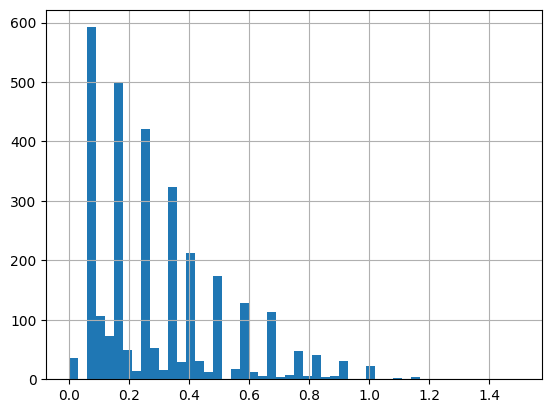

In [ ]:
groups[1]['CASH_ADVANCE_FREQUENCY'].hist(bins=50)

the linear correlation between purchases and oneoff_purchases in cluster 0 is strong with oneoff_purchases making 72% of each person's purchases on average

In [ ]:
group_0_purchase_cor=groups[0][['PURCHASES','ONEOFF_PURCHASES']].corr()
group_0_purchase_cor

,PURCHASES,ONEOFF_PURCHASES
PURCHASES,1.000000,0.913581
ONEOFF_PURCHASES,0.913581,1.000000


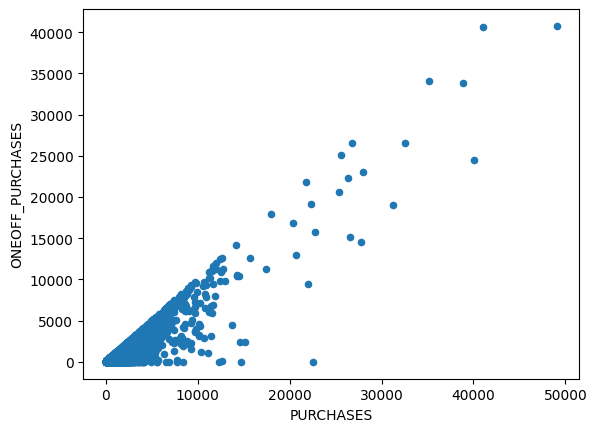

In [ ]:
groups[0][['PURCHASES','ONEOFF_PURCHASES']].plot(kind='scatter',x='PURCHASES',y='ONEOFF_PURCHASES')
plt.show()

In [ ]:
m,b=np.polyfit(groups[0]['PURCHASES'],groups[0]['ONEOFF_PURCHASES'],1)
print(f' m:{m}')
print(f' b:{b}')

 m:0.7221950037172893
 b:-202.9333278062625


## General Insights
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.
3. 69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers

4.  more than 65% of people do not pay full payment ever
5. Portion for One-off purchases is fixed in the purchases of customers(72%)
6. It also looks like that some frequencies  balnce_frequencie are unnaturally cut off at 1.(what is the reason? how was data collected?)


## Characteristics, differences and Interpretation of Clusters
### Cluster 0
1. Cluster 0 consists of people who use the credit card  to pay the merchant directly.
2. These people usually have lower debts
3. They have consumed less proportion of their credit card limit.
4.  They are in the majority
5.  A significant portion of the clientle in this cluster are active to the highest degree and  ohters are thinly spread among the remaining degrees
6. They do more no of borrowing transactions (as compared to cluster 1) and on average take out  a lower debt(relative to cluster 1) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 1.
8. There are significant hardliners of installments and oneofff purchases(54%)   present in this group.
9.  cluster 0 is behind cluster 1 in borrowing frequency.
10. They are the lower-risk core customer base
11. the linear correlation between purchases and oneoff_purchases in cluster 0 is strong with oneoff_purchases making 72% of each person's purchases on average


### Cluster 1
1. As a contrast to this there is cluster 1 which consist of people who use the credit card to get cash.
2. They take cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently.

3. They ususally have higher debts.
4. They have consumed more proportion of their credit card limit.
5. They are less in numbers than cluster 0.
6. They do less no of borrowing transactions (as compared to cluster 0) and on average take out  a higher  debt(relative to cluster 0) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 0.
8. cluster 1 is ahead of cluster 0 in borrowing frequency.
9. They are the higher-margin but higher-risk part of the customer base.



#Week 5 (new)

1. **Preprocessing**

2. **Segment assignment for new customers** — `assign_segment()` reuses the fitted  pipeline and returns a **confidence** score (distance-to-centroid), flagging borderline cases.
3. **Recommendation engine** — a  rule-based layer that combines *segment membership* with  KPI thresholds*. Each rule states its **rationale** and the **business KPI** it targets.

4. **recommending for new customers**
5. **running it on the current data**
6. **Evaluation, limitations and responsible-use.**



## 5.1 Preprocessing

In [ ]:
import numpy as np
import pandas as pd


BASE_COLUMNS = list(cc_explore.columns)
def safe(n, d):
        return (n / d).replace([np.inf, -np.inf], np.nan).fillna(0)

def build_features(df):

    out = df.reindex(columns=BASE_COLUMNS).copy()
    out['credit_util']        = safe(out['BALANCE'], out['CREDIT_LIMIT'])
    out['cash_reliance']      = safe(out['CASH_ADVANCE'], out['PURCHASES'] + out['CASH_ADVANCE'])
    out['payment_to_min']     = safe(out['PAYMENTS'], out['MINIMUM_PAYMENTS'])
    out['avg_purchase_value'] = safe(out['PURCHASES'], out['PURCHASES_TRX'])
    out['total_trx']          = out['PURCHASES_TRX'] + out['CASH_ADVANCE_TRX']
    return out


enhanced_rebuilt = build_features(cc_explore)
assert list(enhanced_rebuilt.columns) == list(enhanced_cc.columns), "column order/name mismatch"


## 5.2 Naming the segments

Cluster identity is derived from the centroids. KMeans may assign different integer
labels on different runs. The segment with higher mean cash_reliance is the Cash-Advance Revolvers; the other is the
Transactors.

In [ ]:
_lbl = kmean_pipeline['kmean'].labels_
_by_cash = enhanced_rebuilt.assign(cluster=_lbl).groupby('cluster')['cash_reliance'].mean()
REVOLVER   = int(_by_cash.idxmax())
TRANSACTOR = int(_by_cash.idxmin())

SEGMENTS = {
    TRANSACTOR: {
        'name': 'Transactors',
        'profile': ('Use the card mainly to pay merchants directly. Lower utilization, lower revolving '
                    'balances, Majority segment (~65%). '
                    'Lower-risk core of the book.'),
    },
    REVOLVER: {
        'name': 'Cash-Advance Revolvers',
        'profile': ('Rely more on cash advances (spent outside the card network), carry higher balances and '
                    'utilization, and larger borrowing frequency. Smaller segment (~35%). '
                    'Higher-margin (interest/fees) but statistically higher-risk.'),
    },
}
for k, v in SEGMENTS.items():
    print(f"[label {k}] {v['name']}\n    {v['profile']}\n")

[label 0] Transactors
    Use the card mainly to pay merchants directly. Lower utilization, lower revolving balances, Majority segment (~65%). Lower-risk core of the book.

[label 1] Cash-Advance Revolvers
    Rely more on cash advances (spent outside the card network), carry higher balances and utilization, and larger borrowing frequency. Smaller segment (~35%). Higher-margin (interest/fees) but statistically higher-risk.



## 5.3  Decision thresholds



In [ ]:
THRESHOLDS = {
    'util_low'   : float(enhanced_rebuilt['credit_util'].quantile(0.33)),   # bottom third of utilization
    'util_high'  : float(enhanced_rebuilt['credit_util'].quantile(0.66)),   # top third
    'util_vhigh' : float(enhanced_rebuilt['credit_util'].quantile(0.90)),   # near-limit stress zone
    'pay_strong' : float(enhanced_rebuilt['payment_to_min'].quantile(0.60)),# comfortably above minimum
    'purch_high' : float(enhanced_rebuilt['PURCHASES'].quantile(0.66)),     # high spend
    'cash_heavy' : 0.50,   # >=50% of card 'outflow' is cash advance
    'freq_active': 0.50,   # PURCHASES_FREQUENCY below this is under-engaged (in cluster 0)
    'conf_border': 0.55,   # assignment-confidence floor before we act automatically
}
for k, v in THRESHOLDS.items():
    print(f"{k:12s}: {v:.3f}")

util_low    : 0.086
util_high   : 0.544
util_vhigh  : 0.920
pay_strong  : 3.200
purch_high  : 740.311
cash_heavy  : 0.500
freq_active : 0.500
conf_border : 0.550


## 5.4 Recommendation rules



| # | Fires for | Condition | Action | Justification | Target business KPI |
|---|-----------|-----------|--------|-----------------------------------------------|---------------------|
| R1 | Transactor | `util < util_low` **and** `payment_to_min ≥ pay_strong` **and** not borderline | Pre-approve credit-limit increase | Unused capacity + servicing above minimum ⇒ headroom converts to spend with limited incremental default risk | Interchange/spend uplift; PD flat |
| R2 | Transactor | `purch_freq ≥ freq_active` **and** `PURCHASES ≥ purch_high` | Rewards / premium-card upgrade | Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share | Interchange revenue; retention |
| R3 | Transactor | `purch_freq < freq_active` | Targeted activation nudges | A sizeable portion of this segment sits below peak activity; reliable users are cheap to reactivate | Active-rate; monthly spend |
| R4 | Transactor | always (low priority) | Offer one-off → installment conversion | Segment is one-off heavy (~70% of purchases); optional plans add interest income from willing low-risk payers | Interest income |
| R5 | Revolver | `cash_reliance > cash_heavy` **or** `util > util_high` | Lower-APR installment / consolidation loan **replacing** cash advances | Cash advances charge interest from day one at a high rate; a cheaper structured product lowers customer cost **and** improves repayment odds while retaining the balance  | Roll-to-delinquency ↓; balances retained |
| R6 | Revolver | `util > util_vhigh` | Near-limit / high-utilization alerts | Utilization above the 90th percentile is a leading stress signal; alerts cut over-limit and missed-payment events | Over-limit incidents; delinquency |
| R7 | Revolver | always (medium) | **Hold**  credit-limit increases pending 2–3 cycles | Elevated utilization + slower repayment are associated with higher risk.| Expected loss; fair-treatment |
| R8 | Revolver | `payment_to_min < 1` **or** `full_pay_rate < 0.05` | Autopay + reminders + hardship/financial-wellness tools | Paying at/below the minimum with ~0 full-payment raises delinquency odds; support is the responsible-use action **before** any risk action | Delinquency ↓; customer welfare |
| R9 | Any | `conf < conf_border` | Route to manual review; conservative defaults | Customer sits near the segment boundary; avoid automated credit decisions on an uncertain assignment | Decision quality; risk of error |




Assign raw-schema customer rows to a segment.
Confidence in [0.5..1): 0.5 means it is exactly on the
boundary between the two centroids, If it is close to 1 that means it is firmly inside one segment.

In [ ]:
def assign_segment(new_df):

    feats = build_features(new_df)
    Xn = kmean_pipeline['preprocessing'].transform(feats)
    dist = kmean_pipeline['kmean'].transform(Xn)
    labels = dist.argmin(axis=1)
    nearest_two = np.sort(dist, axis=1)[:, :2]
    conf = 1 - nearest_two[:, 0] / (nearest_two[:, 0] + nearest_two[:, 1])
    return labels, conf

In [ ]:
def _kpis(frow):
    return {
        'credit_util'   : float(frow['credit_util']),
        'cash_reliance' : float(frow['cash_reliance']),
        'payment_to_min': float(frow['payment_to_min']),
        'purch_freq'    : float(frow['PURCHASES_FREQUENCY']),
        'purchases'     : float(frow['PURCHASES']),
        'full_pay_rate' : float(frow['PRC_FULL_PAYMENT']),
    }

def recommend(customer_row, label, confidence, thresholds=THRESHOLDS):
    #Return a prioritised list of actions for one customer.

    T = thresholds
    k = _kpis(customer_row)
    borderline = confidence < T['conf_border']
    recs = []
    def add(priority, action, rationale, kpi, rule):
        recs.append({'rule': rule, 'priority': priority, 'action': action,
                     'rationale': rationale, 'target_kpi': kpi})

    if label == TRANSACTOR:
        if k['credit_util'] < T['util_low'] and k['payment_to_min'] >= T['pay_strong'] and not borderline:
            add(1, 'Pre-approve a credit-limit increase',
                f"Low utilization ({k['credit_util']:.2f}) with repayment well above the minimum "
                f"({k['payment_to_min']:.1f}x) signals unused capacity and consistent servicing.",
                'Spend/interchange uplift at flat PD', 'R1')
        if k['purch_freq'] >= T['freq_active'] and k['purchases'] >= T['purch_high']:
            add(2, 'Offer rewards / premium-card upgrade',
                'Frequent, high-volume merchant spend monetises through interchange; rewards deepen wallet share.',
                'Interchange revenue; retention', 'R2')
        if k['purch_freq'] < T['freq_active']:
            add(2, 'Send targeted activation nudges (offers, category boosts)',
                f"Under-engaged (purchase frequency {k['purch_freq']:.2f}); reliable users are low-cost to reactivate.",
                'Active-rate; monthly spend', 'R3')
        add(3, 'Offer one-off -> installment conversion at point of sale',
            'Segment is one-off heavy; optional installment plans add interest income from a low-risk payer.',
            'Interest income', 'R4')
    else:  # REVOLVER
        if k['cash_reliance'] > T['cash_heavy'] or k['credit_util'] > T['util_high']:
            add(1, 'Offer a lower-APR installment / consolidation loan to replace cash advances',
                f"High cash reliance ({k['cash_reliance']:.2f}) / utilization ({k['credit_util']:.2f}); a cheaper "
                'structured product lowers borrowing cost and improves repayment odds while retaining the balance.',
                'Roll-to-delinquency down; balances retained', 'R5')
        if k['credit_util'] > T['util_vhigh']:
            add(1, 'Enable near-limit / high-utilization alerts',
                f"Utilization ({k['credit_util']:.2f}) is above the 90th percentile — a leading stress signal.",
                'Over-limit incidents; delinquency', 'R6')
        add(2, 'Hold (do not cut) credit-limit increases pending 2-3 repayment cycles',
            'Elevated utilization with slower repayment is associated with higher risk; holding is the proportionate step.',
            'Expected loss; fair-treatment', 'R7')
        if k['payment_to_min'] < 1.0 or k['full_pay_rate'] < 0.05:
            add(1, 'Enroll in autopay + reminders; surface hardship / financial-wellness tools',
                f"Paying {k['payment_to_min']:.2f}x the minimum with full-payment rate {k['full_pay_rate']:.2f} "
                'raises delinquency odds; support is the responsible first action.',
                'Delinquency rate; customer welfare', 'R8')


    if borderline:
        add(1, 'Route to manual review - segment assignment is borderline',
            f'Near the segment boundary (confidence {confidence:.2f}); apply conservative defaults, no automated credit change.',
            'Decision quality', 'R9')

    recs.sort(key=lambda r: r['priority'])
    return recs

def recommend_for_new_customer(new_df, verbose=True):
    # segment + confidence + prioritised actions.
    labels, conf = assign_segment(new_df)
    feats = build_features(new_df)
    results = []
    for i in range(len(new_df)):
        lab, c = int(labels[i]), float(conf[i])
        recs = recommend(feats.iloc[i], lab, c)
        results.append({'segment': SEGMENTS[lab]['name'], 'label': lab, 'confidence': c, 'recommendations': recs})
        if verbose:
            print(f"\nSegment: {SEGMENTS[lab]['name']}  (confidence {c:.2f})")
            for r in recs:
                print(f"  [P{r['priority']}][{r['rule']}] {r['action']}")
                print(f"        why : {r['rationale']}")
                print(f"        KPI : {r['target_kpi']}")
    return results

## 5.5 Recommendation examples for new customers

Three representative new customers are assigned and scored end-to-end. Median values are used for unspecified fields so
each example isolates one behavioural profile.

In [ ]:
def make_new_customer(**kw):
    base = cc_explore.median(numeric_only=True).to_dict()
    base.update(kw)
    return pd.DataFrame([base])[BASE_COLUMNS]

new_customers = {
 'A. Low-risk frequent transactor': make_new_customer(
        BALANCE=200, CASH_ADVANCE=0, PURCHASES=4000, ONEOFF_PURCHASES=3000, INSTALLMENTS_PURCHASES=1000,
        PURCHASES_FREQUENCY=0.9, PURCHASES_TRX=40, CASH_ADVANCE_TRX=0, CREDIT_LIMIT=8000,
        PAYMENTS=4200, MINIMUM_PAYMENTS=300, PRC_FULL_PAYMENT=0.9),
 'B. Heavy cash-advance revolver': make_new_customer(
        BALANCE=7000, CASH_ADVANCE=6000, PURCHASES=100, ONEOFF_PURCHASES=100, INSTALLMENTS_PURCHASES=0,
        PURCHASES_FREQUENCY=0.1, CASH_ADVANCE_FREQUENCY=0.8, PURCHASES_TRX=2, CASH_ADVANCE_TRX=15,
        CREDIT_LIMIT=8000, PAYMENTS=800, MINIMUM_PAYMENTS=900, PRC_FULL_PAYMENT=0.0),
 'C. Dormant low-utilization transactor': make_new_customer(
        BALANCE=50, CASH_ADVANCE=0, PURCHASES=150, ONEOFF_PURCHASES=150, INSTALLMENTS_PURCHASES=0,
        PURCHASES_FREQUENCY=0.1, PURCHASES_TRX=3, CASH_ADVANCE_TRX=0, CREDIT_LIMIT=6000,
        PAYMENTS=200, MINIMUM_PAYMENTS=60, PRC_FULL_PAYMENT=0.5),
}
for name, cust in new_customers.items():
    print('='*90); print(name)
    recommend_for_new_customer(cust)

A. Low-risk frequent transactor

Segment: Transactors  (confidence 0.66)
  [P1][R1] Pre-approve a credit-limit increase
        why : Low utilization (0.03) with repayment well above the minimum (14.0x) signals unused capacity and consistent servicing.
        KPI : Spend/interchange uplift at flat PD
  [P2][R2] Offer rewards / premium-card upgrade
        why : Frequent, high-volume merchant spend monetises through interchange; rewards deepen wallet share.
        KPI : Interchange revenue; retention
  [P3][R4] Offer one-off -> installment conversion at point of sale
        why : Segment is one-off heavy; optional installment plans add interest income from a low-risk payer.
        KPI : Interest income
B. Heavy cash-advance revolver

Segment: Cash-Advance Revolvers  (confidence 0.63)
  [P1][R5] Offer a lower-APR installment / consolidation loan to replace cash advances
        why : High cash reliance (0.98) / utilization (0.88); a cheaper structured product lowers borrowing cost an

## 5.6 running recommendation layer on the current data

Running the engine over the whole (existing) customer base

In [ ]:
labels_all, conf_all = assign_segment(cc_explore)
feats_all = build_features(cc_explore)

from collections import Counter
action_counts = Counter()
seg_counts = Counter()
for i in range(len(cc_explore)):
    seg_counts[SEGMENTS[int(labels_all[i])]['name']] += 1
    for r in recommend(feats_all.iloc[i], int(labels_all[i]), float(conf_all[i])):
        action_counts[f"[{r['rule']}] {r['action']}"] += 1

n = len(cc_explore)
print(f"Total customers: {n}\n")
print("Segment sizes:")
for s, c in seg_counts.items():
    print(f"  {s:26s}: {c:5d}  ({c/n:5.1%})")
print(f"\nBorderline (confidence < {THRESHOLDS['conf_border']}): "
      f"{(conf_all < THRESHOLDS['conf_border']).sum()}  ({(conf_all < THRESHOLDS['conf_border']).mean():.1%})\n")
print("Action reach (share of book):")
for action, c in action_counts.most_common():
    print(f"  {c/n:5.1%}  {action}")

Total customers: 8950

Segment sizes:
  Transactors               :  5856  (65.4%)
  Cash-Advance Revolvers    :  3094  (34.6%)

Borderline (confidence < 0.55): 1388  (15.5%)

Action reach (share of book):
  65.4%  [R4] Offer one-off -> installment conversion at point of sale
  34.6%  [R7] Hold (do not cut) credit-limit increases pending 2-3 repayment cycles
  34.3%  [R5] Offer a lower-APR installment / consolidation loan to replace cash advances
  28.6%  [R8] Enroll in autopay + reminders; surface hardship / financial-wellness tools
  28.5%  [R2] Offer rewards / premium-card upgrade
  17.6%  [R3] Send targeted activation nudges (offers, category boosts)
  16.8%  [R1] Pre-approve a credit-limit increase
  15.5%  [R9] Route to manual review - segment assignment is borderline
   5.0%  [R6] Enable near-limit / high-utilization alerts


###**Evaluation, limitations & responsible use**

**How we evaluate the approach**
1. The approach uses kmeans clustering to identify potential clusters. This is only valid if the supposed clusters are circular and not any other shape(like elliptical)

2. The two cluster argument is also supported by visuals.

3. Much of the recommendation is driven by kpis and decision thresholds because clusters are not clear cut (silhouette_score ~0.2).



**Limitations**
1. **Unsupervised foundation** — segments are behavioural clusters identified throug an algorithm. We dont know for certain whether they map onto real world.
2. **Snapshot data** — features are a single window; a customer's behaviour (and therefore segment) can drift over time,
   so assignment should be re-run periodically.
3. **Modest separation** — silhouette ~0.27 means segments overlap




# Insight report(week 5)
## General Insights
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.
3. 69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers

4.  more than 65% of people do not pay full payment ever
5. Portion for One-off purchases is fixed in the purchases of customers(70%)
6. It also looks like that some frequencies  balnce_frequencie are unnaturally cut off at 1.(what is the reason? how was data collected?)

## The most dominant pattern CASH_ADVANCE
cluster 0 consumers use credit card for purchases transfering money directly to merchants(as the credit card is meant to be used ).Cluster 1 is smaller than Cluster 0. They take cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently



## Debt
cluster 0 customers have lower debt and have consumed lower proprtion of their credit limit. Cluster 1 customers are closer to their credit limit and have more debt to the bank


## PAYMENT TO BALANCE Ratio
cluster 0 have done more payment for one unit of debt they have. If we combine that with the fact that they generally have lower balance(ie debt) this means they payback quickly and dont let balance pile up

On the other hand cluster 1 have smaller ratio, consistent with carrying revolving balances for longer

## BALANCE_FREQUENCY show no difference
both groups inherit the pattern of the overall data set where a significant portion of the clientle are active to the highest degree and customers are thinly spread among the remining degrees

## cluster 1 takes cash out in larger amounts and and pays it back incrementally
both clusters have the same balance_frequency but cluster 1 has less total_trx. on the other hand avg_transact_value is greater for cluster1. That is cluster1 customers  borrow money in larger amounts and in fewer number of transactions.Given that both clusters exhibit similar balance frequency, Cluster 1 customers would likely repay their larger cash advances over a greater number of installments, with each installment representing a smaller amount on average.

## installments vs one-off:
 There seem to be quite a few hardliners in cluster 0 with installments hardliners being more common.

## Borrowing Frequency
36% of cluster 0 is actively doing purchases to the highest frequency.
while a large bulk of cluster 1 are not drawing cash in advance much frequently.
In other words cluster 1 leads cluster 0 in borrwoing frequency.



## Characteristics,differences and Interpretation of Clusters
### Cluster 0
1. Cluster 0 consists of people who use the credit card  to pay the merchant directly.
2. These people usually have lower debts
3. They have consumed less proportion of their credit card limit.
4.  They are in the majority
5.  A significant portion of the clientle in this cluster are active to the highest degree and  ohters are thinly spread among the remaining degrees
6. They do more no of borrowing transactions (as compared to cluster 1) and on average take out  a lower debt(relative to cluster 1) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 1.
8. There are significant hardliners of installments and oneofff purchases(54%)   present in this group.
9.  cluster 0 is behind cluster 1 in borrowing frequency.
10. They are the healthy core customer base
11. the linear correlation between purchases and oneoff_purchases in cluster 0 is strong with oneoff_purchases making 72% of each person's purchases on average


### Cluster 1
1. As a contrast to this there is cluster 1 which consist of people who use the credit card to get cash.
2. They take cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently.

3. They ususally have higher debts.
4. They have consumed more proportion of their credit card limit.
5. They are less in numbers than cluster 0.
6. They do less no of borrowing transactions (as compared to cluster 0) and on average take out  a higher  debt(relative to cluster 0) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 0.
8. cluster 1 is ahead of cluster 0 in borrowing frequency.
9. They are the higher-margin but higher-risk part of the customer base.

## Recommendation Rules
| Rule | Segment | Priority | Condition | Action | Rationale | Target KPI | Is Credit Action |
|---|---|---:|---|---|---|---|---|
| R1 | Transactors | 1 | `util < util_low AND pay_to_min >= pay_strong AND not borderline` | Pre-approve a credit-limit increase | Unused capacity + servicing above minimum → headroom converts to spend at limited incremental risk | Interchange/spend uplift; PD flat | True |
| R2 | Transactors | 2 | `purch_freq >= freq_active AND PURCHASES >= purch_high` | Offer rewards / premium-card upgrade | Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share | Interchange revenue; retention | False |
| R3 | Transactors | 2 | `purch_freq < freq_active` | Send targeted activation nudges | Reliable but under-engaged users are low-cost to reactivate | Active-rate; monthly spend | False |
| R4 | Transactors | 3 | `always (low priority)` | Offer one-off → installment conversion | One-off-heavy segment; optional plans add interest income from low-risk payers | Interest income | False |
| R5 | Cash-Advance Revolvers | 1 | `cash_reliance > cash_heavy OR util > util_high` | Offer lower-APR installment / consolidation loan for cash advances | Cash advances charge interest from day one; a cheaper product lowers cost and improves repayment odds while retaining the balance | Roll-to-delinquency down; balances retained | True |
| R6 | Cash-Advance Revolvers | 1 | `util > util_vhigh` | Enable near-limit / high-utilization alerts | Utilization above the 90th percentile is a leading stress signal | Over-limit incidents; delinquency | False |
| R7 | Cash-Advance Revolvers | 2 | `always (medium)` | Hold (do not cut) credit-limit increases pending 2–3 cycles | Elevated utilization + slower repayment are associated with higher risk; holding is proportionate | Expected loss; fair-treatment | True |
| R8 | Cash-Advance Revolvers | 1 | `pay_to_min < 1 OR full_pay_rate < 0.05` | Enroll in autopay + reminders; surface hardship / wellness tools | Paying at/below minimum with ~0 full payment raises delinquency odds; support is the responsible first action | Delinquency rate; customer welfare | False |
| R9 | Any | 1 | `confidence < conf_border` | Route to manual review — borderline assignment | Near the segment boundary; apply conservative defaults, no automated credit change | Decision quality | False |

## Why the recommendations fit each segment

**Transactors** are the lower-risk, merchant-payment core. The evidence (earlier sections) shows lower balances, lower
utilization, and repayment consistently above the minimum. The rational business move is to grow revenue on proven-safe
customers: extend headroom where utilization is low and servicing is strong (R1), monetise heavy spenders through
rewards/interchange (R2), reactivate those which are under-engaged (R3), and convert one-off spend into interest-bearing
installments (R4). Each rule targets *revenue* because the *risk* is already demonstrated to be low.

**Cash-Advance Revolvers** rely on cash advances, carry higher balances/utilization, and repay a smaller share per cycle.
Cash advances are the most expensive way for them to borrow (interest from day one). So the leading action is to
replace that expensive borrowing with a cheaper structured product (R5) — this lowers *their* cost and improves the
bank's repayment odds simultaneously. Genuine stress signals (very high utilization, sub-minimum payment, ~0 full payment)
trigger alerts and support (R6, R8) rather than punishment, and credit is held, not cut (R7).

**Across both**, uncertain (borderline) assignments never trigger automated credit changes (R9).



###Evaluation, limitations & responsible use

**How we evaluate the approach**
1. The approach uses kmeans clustering to identify potential clusters. This is only valid if the supposed clusters are circular and not any other shape(like elliptical)

2. The two cluster argument is also supported by visuals.

3. Much of the recommendation is driven by kpis and decision thresholds because clusters are not clear cut (silhouette_score ~0.2).



**Limitations**
1. **Unsupervised foundation** segments are behavioural clusters identified throug an algorithm. We dont know for certain whether they map onto real world.
2. **Snapshot data** features are a single window; a customer's behaviour (and therefore segment) can drift over time,
   so assignment should be re-run periodically.
3. **Modest separation** silhouette ~0.27 means segments overlap




# WEEK 6 — Customer Intelligence & Action Recommendation System



**Improvements**
1. recalibrated,calculated assignment confidence(instead of guesswork).
2. Rules moved into a dataframe.
3. assign intensity to actions and actions are tied to confidence scores.
4.  Re-run examples and population view with the improved engine.
5.  segment-profile table, segment fingerprint and a 2-D PCA map with a new customer placed on it
6.  Persist the whole system to a single deployable artifact.

## 6.1 Recalibrated confidence, borderline threshold & intensity tiers

The Week-5 confidence `1 - d_near/(d_near+d_far)`  ranges over **[0.5, 1)**,
**margin** `(d_far - d_near)/(d_far + d_near)`,  spans the full **[0, 1]**. We  set the borderline cut-off from the data (10th percentile of population
confidence) and derive **intensity tiers** (Soft / Moderate / Strong) from the confidence tertiles.

In [ ]:
# Redefine assign_segment with the margin-based confidence (full [0,1] range)
def assign_segment(new_df):
    # returns (labels, confidence); confidence 0 = on the boundary, ->1 = firmly inside a segment
    feats = build_features(new_df)
    Xn = kmean_pipeline['preprocessing'].transform(feats)
    dist = kmean_pipeline['kmean'].transform(Xn)                 # distance to each centroid
    labels = dist.argmin(axis=1)
    nearest_two = np.sort(dist, axis=1)[:, :2]
    d_near, d_far = nearest_two[:, 0], nearest_two[:, 1]
    conf = (d_far - d_near) / (d_far + d_near)
    return labels, conf

# Recalibrate the borderline threshold + intensity cut-offs from the actual distribution
_, _conf_pop = assign_segment(cc_explore)
print("Population confidence percentiles:")
for q in [1, 5, 10, 25, 33, 50, 66, 90]:
    print(f"  {q:2d}th: {np.percentile(_conf_pop, q):.3f}")

THRESHOLDS['conf_border'] = float(np.percentile(_conf_pop, 10))
INTENSITY_CUTS = (float(np.percentile(_conf_pop, 33)), float(np.percentile(_conf_pop, 66)))

def intensity_from_confidence(confidence, cuts=None):
    # higher assignment confidence -> more proactive delivery of the same action
    lo, hi = cuts if cuts is not None else INTENSITY_CUTS
    return 'Strong' if confidence >= hi else ('Moderate' if confidence >= lo else 'Soft')

print(f"\nRecalibrated conf_border = {THRESHOLDS['conf_border']:.3f} "
      f"-> flags {(_conf_pop < THRESHOLDS['conf_border']).mean():.1%} of the book for manual review")
print(f"Intensity tiers:  Soft < {INTENSITY_CUTS[0]:.3f} <= Moderate < {INTENSITY_CUTS[1]:.3f} <= Strong")

Population confidence percentiles:
   1th: 0.008
   5th: 0.036
  10th: 0.068
  25th: 0.150
  33th: 0.192
  50th: 0.272
  66th: 0.336
  90th: 0.456

Recalibrated conf_border = 0.068 -> flags 10.0% of the book for manual review
Intensity tiers:  Soft < 0.192 <= Moderate < 0.336 <= Strong


## 6.2 Rules df

The recommendation rules are moved from scattered `if/else` text into one auditable table. `priority`
(1 = act first) and the wording/rationale/KPI now live as data; `is_credit_action` flags rules that
change a credit line or lending product so they can be safely gated on low-confidence assignments.

In [ ]:
import pandas as pd

RULES = [
 # rule, segment,                  priority, condition,                                                     action,                                                              rationale,                                                                                    target_kpi,                              is_credit
 ('R1', 'Transactors',            1, 'util<util_low AND pay_to_min>=pay_strong AND not borderline',        'Pre-approve a credit-limit increase',                               'Unused capacity + servicing above minimum -> headroom converts to spend at limited incremental risk','Interchange/spend uplift; PD flat',    True),
 ('R2', 'Transactors',            2, 'purch_freq>=freq_active AND PURCHASES>=purch_high',                  'Offer rewards / premium-card upgrade',                              'Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share',        'Interchange revenue; retention',        False),
 ('R3', 'Transactors',            2, 'purch_freq<freq_active',                                             'Send targeted activation nudges',                                   'Reliable but under-engaged users are low-cost to reactivate',                                        'Active-rate; monthly spend',            False),
 ('R4', 'Transactors',            3, 'always (low priority)',                                              'Offer one-off -> installment conversion',                           'One-off-heavy segment; optional plans add interest income from low-risk payers',                     'Interest income',                       False),
 ('R5', 'Cash-Advance Revolvers', 1, 'cash_reliance>cash_heavy OR util>util_high',                         'Offer lower-APR installment / consolidation loan for cash advances', 'Cash advances charge interest from day one; a cheaper product lowers cost and improves repayment odds while retaining the balance','Roll-to-delinquency down; balances retained', True),
 ('R6', 'Cash-Advance Revolvers', 1, 'util>util_vhigh',                                                    'Enable near-limit / high-utilization alerts',                       'Utilization above the 90th percentile is a leading stress signal',                                   'Over-limit incidents; delinquency',     False),
 ('R7', 'Cash-Advance Revolvers', 2, 'always (medium)',                                                    'Hold (do not cut) credit-limit increases pending 2-3 cycles',       'Elevated utilization + slower repayment are associated with higher risk; holding is proportionate',  'Expected loss; fair-treatment',         True),
 ('R8', 'Cash-Advance Revolvers', 1, 'pay_to_min<1 OR full_pay_rate<0.05',                                 'Enroll in autopay + reminders; surface hardship / wellness tools',  'Paying at/below minimum with ~0 full payment raises delinquency odds; support is the responsible first action','Delinquency rate; customer welfare',  False),
 ('R9', 'Any',                    1, 'confidence<conf_border',                                             'Route to manual review - borderline assignment',                    'Near the segment boundary; apply conservative defaults, no automated credit change',                 'Decision quality',                      False),
]
RULES_DF = pd.DataFrame(RULES, columns=['rule','segment','priority','condition','action',

                                       'rationale','target_kpi','is_credit_action']).set_index('rule')
pd.set_option('display.max_colwidth', None)

RULES_DF

,segment,priority,condition,action,rationale,target_kpi,is_credit_action
rule,,,,,,,
R1,Transactors,1,util<util_low AND pay_to_min>=pay_strong AND not borderline,Pre-approve a credit-limit increase,Unused capacity + servicing above minimum -> headroom converts to spend at limited incremental risk,Interchange/spend uplift; PD flat,True
R2,Transactors,2,purch_freq>=freq_active AND PURCHASES>=purch_high,Offer rewards / premium-card upgrade,Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share,Interchange revenue; retention,False
R3,Transactors,2,purch_freq<freq_active,Send targeted activation nudges,Reliable but under-engaged users are low-cost to reactivate,Active-rate; monthly spend,False
R4,Transactors,3,always (low priority),Offer one-off -> installment conversion,One-off-heavy segment; optional plans add interest income from low-risk payers,Interest income,False
R5,Cash-Advance Revolvers,1,cash_reliance>cash_heavy OR util>util_high,Offer lower-APR installment / consolidation loan for cash advances,Cash advances charge interest from day one; a cheaper product lowers cost and improves repayment odds while retaining the balance,Roll-to-delinquency down; balances retained,True
R6,Cash-Advance Revolvers,1,util>util_vhigh,Enable near-limit / high-utilization alerts,Utilization above the 90th percentile is a leading stress signal,Over-limit incidents; delinquency,False
R7,Cash-Advance Revolvers,2,always (medium),Hold (do not cut) credit-limit increases pending 2-3 cycles,Elevated utilization + slower repayment are associated with higher risk; holding is proportionate,Expected loss; fair-treatment,True
R8,Cash-Advance Revolvers,1,pay_to_min<1 OR full_pay_rate<0.05,Enroll in autopay + reminders; surface hardship / wellness tools,Paying at/below minimum with ~0 full payment raises delinquency odds; support is the responsible first action,Delinquency rate; customer welfare,False
R9,Any,1,confidence<conf_border,Route to manual review - borderline assignment,"Near the segment boundary; apply conservative defaults, no automated credit change",Decision quality,False


##6.3 coding the changes to action prediction

`recommend()` is redefined to:
1. look up action / priority / rationale / KPI from `RULES_DF`,
2. attach an intensity tier tied to the assignment confidence, and
3. hard-gate credit
actions (skip them) on borderline assignments

In [ ]:
def _fired_rules(k, label, borderline, T):

    fired = []
    if label == TRANSACTOR:
        if k['credit_util'] < T['util_low'] and k['payment_to_min'] >= T['pay_strong'] and not borderline:
            fired.append('R1')
        if k['purch_freq'] >= T['freq_active'] and k['purchases'] >= T['purch_high']:
            fired.append('R2')
        if k['purch_freq'] < T['freq_active']:
            fired.append('R3')
        fired.append('R4')
    else:  # REVOLVER
        if k['cash_reliance'] > T['cash_heavy'] or k['credit_util'] > T['util_high']:
            fired.append('R5')
        if k['credit_util'] > T['util_vhigh']:
            fired.append('R6')
        fired.append('R7')
        if k['payment_to_min'] < 1.0 or k['full_pay_rate'] < 0.05:
            fired.append('R8')
    if borderline:
        fired.append('R9')
    return fired

def recommend(customer_row, label, confidence, thresholds=THRESHOLDS):

    T = thresholds
    k = _kpis(customer_row)
    borderline = confidence < T['conf_border']
    tier = intensity_from_confidence(confidence)
    recs = []
    for rule in _fired_rules(k, label, borderline, T):
        meta = RULES_DF.loc[rule]
        if bool(meta['is_credit_action']) and borderline and rule != 'R9':
            continue
        recs.append({
            'rule'      : rule,
            'priority'  : int(meta['priority']),
            'intensity' : 'Manual review' if rule == 'R9' else tier,
            'confidence': round(float(confidence), 3),
            'action'    : str(meta['action']),
            'rationale' : str(meta['rationale']),
            'target_kpi': str(meta['target_kpi']),
        })
    recs.sort(key=lambda r: (r['priority'], -r['confidence']))
    return recs

def recommend_for_new_customer(new_df, verbose=True):

    labels, conf = assign_segment(new_df)
    feats = build_features(new_df)
    results = []
    for i in range(len(new_df)):
        lab, c = int(labels[i]), float(conf[i])
        recs = recommend(feats.iloc[i], lab, c)
        results.append({'segment': SEGMENTS[lab]['name'], 'label': lab, 'confidence': c,
                        'intensity': intensity_from_confidence(c), 'recommendations': recs})
        if verbose:
            print(f"\nSegment: {SEGMENTS[lab]['name']}  (confidence {c:.2f}, delivery: {intensity_from_confidence(c)})")
            for r in recs:
                print(f"  [P{r['priority']}][{r['rule']}][{r['intensity']}] {r['action']}")
                print(f"        why : {r['rationale']}")
                print(f"        KPI : {r['target_kpi']}")
    return results

## 6.4 Recommendation examples (improved engine)



In [ ]:
for name, cust in new_customers.items():
    print('='*90); print(name)
    recommend_for_new_customer(cust)

A. Low-risk frequent transactor

Segment: Transactors  (confidence 0.32, delivery: Moderate)
  [P1][R1][Moderate] Pre-approve a credit-limit increase
        why : Unused capacity + servicing above minimum -> headroom converts to spend at limited incremental risk
        KPI : Interchange/spend uplift; PD flat
  [P2][R2][Moderate] Offer rewards / premium-card upgrade
        why : Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share
        KPI : Interchange revenue; retention
  [P3][R4][Moderate] Offer one-off -> installment conversion
        why : One-off-heavy segment; optional plans add interest income from low-risk payers
        KPI : Interest income
B. Heavy cash-advance revolver

Segment: Cash-Advance Revolvers  (confidence 0.27, delivery: Moderate)
  [P1][R5][Moderate] Offer lower-APR installment / consolidation loan for cash advances
        why : Cash advances charge interest from day one; a cheaper product lowers cost and improves repa

## 6.5 Population view with the recalibrated engine



In [ ]:
labels_all, conf_all = assign_segment(cc_explore)
feats_all = build_features(cc_explore)

from collections import Counter
action_counts = Counter(); seg_counts = Counter()
for i in range(len(cc_explore)):
    seg_counts[SEGMENTS[int(labels_all[i])]['name']] += 1
    for r in recommend(feats_all.iloc[i], int(labels_all[i]), float(conf_all[i])):
        action_counts[f"[{r['rule']}] {r['action']}"] += 1

n = len(cc_explore)
print(f"Total customers: {n}\n")
print("Segment sizes:")
for s, c in seg_counts.items():
    print(f"  {s:26s}: {c:5d}  ({c/n:5.1%})")
print(f"\nBorderline (confidence < {THRESHOLDS['conf_border']:.3f}): "
      f"{(conf_all < THRESHOLDS['conf_border']).sum()}  ({(conf_all < THRESHOLDS['conf_border']).mean():.1%})\n")
print("Action reach (share of book):")
for action, c in action_counts.most_common():
    print(f"  {c/n:5.1%}  {action}")

Total customers: 8950

Segment sizes:
  Transactors               :  5856  (65.4%)
  Cash-Advance Revolvers    :  3094  (34.6%)

Borderline (confidence < 0.068): 895  (10.0%)

Action reach (share of book):
  65.4%  [R4] Offer one-off -> installment conversion
  30.5%  [R7] Hold (do not cut) credit-limit increases pending 2-3 cycles
  30.4%  [R5] Offer lower-APR installment / consolidation loan for cash advances
  28.6%  [R8] Enroll in autopay + reminders; surface hardship / wellness tools
  28.5%  [R2] Offer rewards / premium-card upgrade
  17.6%  [R3] Send targeted activation nudges
  17.3%  [R1] Pre-approve a credit-limit increase
  10.0%  [R9] Route to manual review - borderline assignment
   5.0%  [R6] Enable near-limit / high-utilization alerts


## 6.6 Segment profiles at a glance

A  view of how the two segments differ on the KPIs that drive the rules.

In [ ]:
PROFILE_COLS = ['credit_util','cash_reliance','payment_to_min','BALANCE','PURCHASES','PRC_FULL_PAYMENT']

_prof = enhanced_rebuilt.copy()
_prof['segment'] = [SEGMENTS[l]['name'] for l in kmean_pipeline['kmean'].labels_]

print("Segment sizes:")
for name, cnt in _prof['segment'].value_counts().items():
    print(f"  {name:26s}: {cnt:5d} ({cnt/len(_prof):.1%})")

segment_profile = _prof.groupby('segment')[PROFILE_COLS].agg(['mean','median']).round(3)
segment_profile

Segment sizes:
  Transactors               :  5856 (65.4%)
  Cash-Advance Revolvers    :  3094 (34.6%)


credit_util        cash_reliance        payment_to_min  \
                              mean median          mean median           mean   
segment                                                                         
Cash-Advance Revolvers       0.591  0.630         0.930    1.0          7.725   
Transactors                  0.282  0.115         0.089    0.0          9.764   

                                BALANCE           PURCHASES          \
                       median      mean    median      mean  median   
segment                                                               
Cash-Advance Revolvers  1.087  2413.131  1624.328    128.41    0.00   
Transactors             2.855  1116.090   384.385   1465.40  734.24   

                       PRC_FULL_PAYMENT         
                                   mean median  
segment                                         
Cash-Advance Revolvers            0.038    0.0  
Transactors                       0.215    0.0

## 6.7 Comparative visuals (presentation layer)

1. **Segment fingerprint** each KPI standardized then averaged per
   segment
2. **2-D PCA map** of the clustering space, coloured by segment, with a **new customer** placed on it.

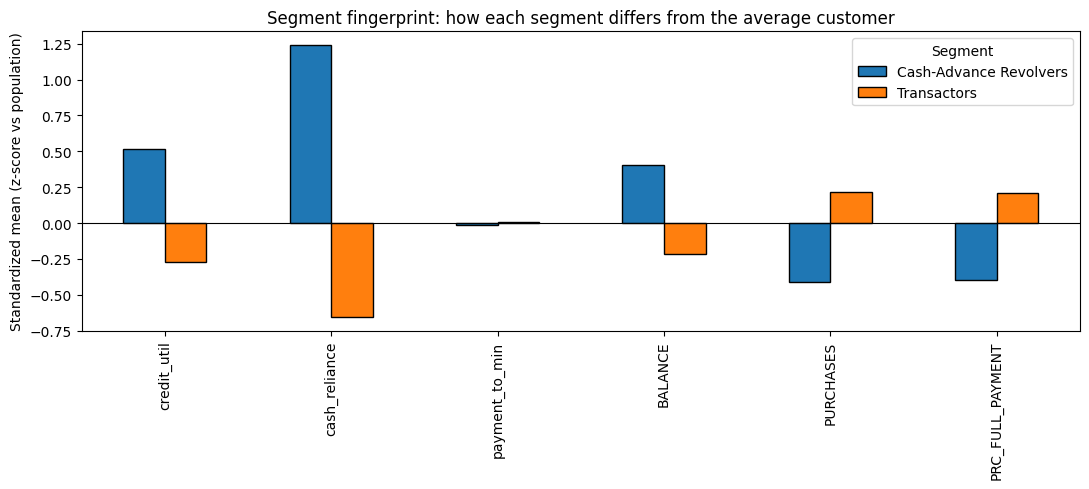

In [ ]:
import matplotlib.pyplot as plt

# 1. Segment fingerprint: standardized KPI means per segment
_z = (_prof[PROFILE_COLS] - _prof[PROFILE_COLS].mean()) / _prof[PROFILE_COLS].std()
_z['segment'] = _prof['segment'].values
seg_z = _z.groupby('segment')[PROFILE_COLS].mean()

ax = seg_z.T.plot(kind='bar', figsize=(11, 5), edgecolor='black')
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Standardized mean (z-score vs population)')
ax.set_title('Segment fingerprint: how each segment differs from the average customer')
ax.legend(title='Segment')
plt.tight_layout(); plt.show()

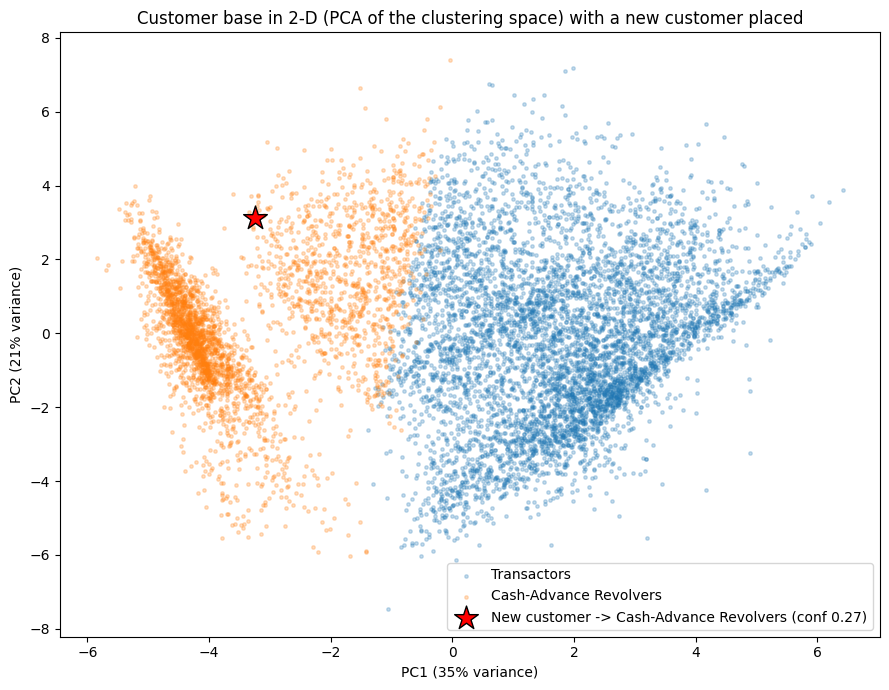

In [ ]:
from sklearn.decomposition import PCA

# 2. 2-D PCA map with a new customer placed on it
Xtr = kmean_pipeline['preprocessing'].transform(enhanced_rebuilt)
pca = PCA(n_components=2, random_state=42).fit(Xtr)
P2 = pca.transform(Xtr)
labs = kmean_pipeline['kmean'].labels_

plt.figure(figsize=(9, 7))
for l in sorted(set(labs)):
    m = labs == l
    plt.scatter(P2[m, 0], P2[m, 1], s=6, alpha=0.25, label=SEGMENTS[l]['name'])

_new = make_new_customer(BALANCE=7000, CASH_ADVANCE=6000, PURCHASES=100, ONEOFF_PURCHASES=100,
        INSTALLMENTS_PURCHASES=0, PURCHASES_FREQUENCY=0.1, CASH_ADVANCE_FREQUENCY=0.8, PURCHASES_TRX=2,
        CASH_ADVANCE_TRX=15, CREDIT_LIMIT=8000, PAYMENTS=800, MINIMUM_PAYMENTS=900, PRC_FULL_PAYMENT=0.0)
_lab_new, _conf_new = assign_segment(_new)
_p_new = pca.transform(kmean_pipeline['preprocessing'].transform(build_features(_new)))
plt.scatter(_p_new[0, 0], _p_new[0, 1], c='red', s=320, marker='*', edgecolor='black', zorder=5,
            label=f"New customer -> {SEGMENTS[int(_lab_new[0])]['name']} (conf {float(_conf_new[0]):.2f})")

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)')
plt.title('Customer base in 2-D (PCA of the clustering space) with a new customer placed')
plt.legend(); plt.tight_layout(); plt.show()

## 6.8 Persisting the model

Everything needed to assign a new customer and generate recommendations in a fresh session is saved to
one `joblib` artifact

In [ ]:
import joblib, sklearn

MODEL_ARTIFACT = {
    'pipeline'        : kmean_pipeline,
    'base_columns'    : BASE_COLUMNS,
    'segments'        : SEGMENTS,
    'transactor_label': TRANSACTOR,
    'revolver_label'  : REVOLVER,
    'thresholds'      : THRESHOLDS,
    'intensity_cuts'  : INTENSITY_CUTS,
    'rules'           : RULES_DF.reset_index().to_dict(orient='records'),
    'sklearn_version' : sklearn.__version__,
}
joblib.dump(MODEL_ARTIFACT, 'virexo_segmenter.joblib')
print('Saved -> virexo_segmenter.joblib')

_loaded = joblib.load('virexo_segmenter.joblib')
_lab, _conf = assign_segment(cc_explore.head(3))
print('Reload OK | sklearn', _loaded['sklearn_version'],
      '| segments:', {k: v['name'] for k, v in _loaded['segments'].items()},
      '| conf_border', round(_loaded['thresholds']['conf_border'], 3))

Saved -> virexo_segmenter.joblib
Reload OK | sklearn 1.6.1 | segments: {0: 'Transactors', 1: 'Cash-Advance Revolvers'} | conf_border 0.068




**Improvements**
1. recalibrated,calculated assignment confidence(instead of guesswork).
2. Rules moved into a dataframe.
3. assign intensity to actions and actions are tied to confidence scores.
4.  Re-run examples and population view with the improved engine.
5.  segment-profile table, segment fingerprint and a 2-D PCA map with a new customer placed on it
6.  Persist the whole system to a single deployable artifact.

**Limitations**

- **Unsupervised foundation**  segments are behavioural clusters identified throug an algorithm. We dont know for certain whether they map onto real world.
- **Snapshot data** features are a single window; a customer's behaviour (and therefore segment) can drift over time,
   so assignment should be re-run periodically.
- **Modest separation** silhouette ~0.27 means segments overlap
- **need for more information**:more information fields about the customers can help the model adapt better


**Responsible use**
- Recommendations are **decision-support**, subject to human review and should be considered as consulting material rather than absolute authority.
- While incorporating the model's suggestions into decisions, it would be helpful to first determine why the model predicted what it did and are there any aspects that it has overlooked.

# Formal report

#**Summary of Findings**
## General Insights
1. 51 percent of people only make purchases and take no cash in advance
2. 22% of people only take cash in advance and not make purchases.
3. 69% of the people use their creditcard to the highest degree of frequency
remaining 31% are thinly spread among lower frequencies and bank can introduce perks to intice the remaining inactive customers

4.  more than 65% of people do not pay full payment ever
5. Portion for One-off purchases is fixed in the purchases of customers(70%)
6. It also looks like that some frequencies  balnce_frequencie are unnaturally cut off at 1.(what is the reason? how was data collected?)

## The most dominant pattern CASH_ADVANCE
cluster 0 consumers use credit card for purchases transfering money directly to merchants(as the credit card is meant to be used ).Cluster 1 is smaller than Cluster 0. They take cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently



## Debt
cluster 0 customers have lower debt and have consumed lower proprtion of their credit limit. Cluster 1 customers are closer to their credit limit and have more debt to the bank


## PAYMENT TO BALANCE Ratio
cluster 0 have done more payment for one unit of debt they have. If we combine that with the fact that they generally have lower balance(ie debt) this means they payback quickly and dont let balance pile up

On the other hand cluster 1 have smaller ratio, consistent with carrying revolving balances for longer

## BALANCE_FREQUENCY show no difference
both groups inherit the pattern of the overall data set where a significant portion of the clientle are active to the highest degree and customers are thinly spread among the remining degrees

## cluster 1 takes cash out in larger amounts and and pays it back incrementally
both clusters have the same balance_frequency but cluster 1 has less total_trx. on the other hand avg_transact_value is greater for cluster1. That is cluster1 customers  borrow money in larger amounts and in fewer number of transactions.Given that both clusters exhibit similar balance frequency, Cluster 1 customers would likely repay their larger cash advances over a greater number of installments, with each installment representing a smaller amount on average.

## installments vs one-off:
 There seem to be quite a few hardliners in cluster 0 with installments hardliners being more common.

## Borrowing Frequency
36% of cluster 0 is actively doing purchases to the highest frequency.
while a large bulk of cluster 1 are not drawing cash in advance much frequently.
In other words cluster 1 leads cluster 0 in borrwoing frequency.



## Characteristics,differences and Interpretation of Clusters
### Cluster 0
1. Cluster 0 consists of people who use the credit card  to pay the merchant directly.
2. These people usually have lower debts
3. They have consumed less proportion of their credit card limit.
4.  They are in the majority
5.  A significant portion of the clientle in this cluster are active to the highest degree and  ohters are thinly spread among the remaining degrees
6. They do more no of borrowing transactions (as compared to cluster 1) and on average take out  a lower debt(relative to cluster 1) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 1.
8. There are significant hardliners of installments and oneofff purchases(54%)   present in this group.
9.  cluster 0 is behind cluster 1 in borrowing frequency.
10. They are the healthy core customer base
11. the linear correlation between purchases and oneoff_purchases in cluster 0 is strong with oneoff_purchases making 72% of each person's purchases on average


### Cluster 1
1. As a contrast to this there is cluster 1 which consist of people who use the credit card to get cash.
2. They take cash in advance a lot and spend it outside of the credit card system . There are stricter interest conditions for this kind of cash withdrawl which may suggest that they need money urgently.

3. They ususally have higher debts.
4. They have consumed more proportion of their credit card limit.
5. They are less in numbers than cluster 0.
6. They do less no of borrowing transactions (as compared to cluster 0) and on average take out  a higher  debt(relative to cluster 0) per transaction
7. They have the same balance_frequency(degree of interaction) as cluster 0.
8. cluster 1 is ahead of cluster 0 in borrowing frequency.
9. They are the higher-margin but higher-risk part of the customer base.

## **Recommendation Rules**
| Rule | Segment | Priority | Condition | Action | Rationale | Target KPI | Is Credit Action |
|---|---|---:|---|---|---|---|---|
| R1 | Transactors | 1 | `util < util_low AND pay_to_min >= pay_strong AND not borderline` | Pre-approve a credit-limit increase | Unused capacity + servicing above minimum → headroom converts to spend at limited incremental risk | Interchange/spend uplift; PD flat | True |
| R2 | Transactors | 2 | `purch_freq >= freq_active AND PURCHASES >= purch_high` | Offer rewards / premium-card upgrade | Frequent high-volume merchant spend monetises via interchange; rewards deepen wallet share | Interchange revenue; retention | False |
| R3 | Transactors | 2 | `purch_freq < freq_active` | Send targeted activation nudges | Reliable but under-engaged users are low-cost to reactivate | Active-rate; monthly spend | False |
| R4 | Transactors | 3 | `always (low priority)` | Offer one-off → installment conversion | One-off-heavy segment; optional plans add interest income from low-risk payers | Interest income | False |
| R5 | Cash-Advance Revolvers | 1 | `cash_reliance > cash_heavy OR util > util_high` | Offer lower-APR installment / consolidation loan for cash advances | Cash advances charge interest from day one; a cheaper product lowers cost and improves repayment odds while retaining the balance | Roll-to-delinquency down; balances retained | True |
| R6 | Cash-Advance Revolvers | 1 | `util > util_vhigh` | Enable near-limit / high-utilization alerts | Utilization above the 90th percentile is a leading stress signal | Over-limit incidents; delinquency | False |
| R7 | Cash-Advance Revolvers | 2 | `always (medium)` | Hold (do not cut) credit-limit increases pending 2–3 cycles | Elevated utilization + slower repayment are associated with higher risk; holding is proportionate | Expected loss; fair-treatment | True |
| R8 | Cash-Advance Revolvers | 1 | `pay_to_min < 1 OR full_pay_rate < 0.05` | Enroll in autopay + reminders; surface hardship / wellness tools | Paying at/below minimum with ~0 full payment raises delinquency odds; support is the responsible first action | Delinquency rate; customer welfare | False |
| R9 | Any | 1 | `confidence < conf_border` | Route to manual review — borderline assignment | Near the segment boundary; apply conservative defaults, no automated credit change | Decision quality | False |

## **Why the recommendations fit each segment**

**Transactors** are the lower-risk, merchant-payment core. The evidence (earlier sections) shows lower balances, lower
utilization, and repayment consistently above the minimum. The rational business move is to grow revenue on proven-safe
customers: extend headroom where utilization is low and servicing is strong (R1), monetise heavy spenders through
rewards/interchange (R2), reactivate those which are under-engaged (R3), and convert one-off spend into interest-bearing
installments (R4). Each rule targets *revenue* because the *risk* is already demonstrated to be low.

**Cash-Advance Revolvers** rely on cash advances, carry higher balances/utilization, and repay a smaller share per cycle.
Cash advances are the most expensive way for them to borrow (interest from day one). So the leading action is to
replace that expensive borrowing with a cheaper structured product (R5) — this lowers *their* cost and improves the
bank's repayment odds simultaneously. Genuine stress signals (very high utilization, sub-minimum payment, ~0 full payment)
trigger alerts and support (R6, R8) rather than punishment, and credit is held, not cut (R7).

**Across both**, uncertain (borderline) assignments never trigger automated credit changes (R9).

##**Justifying the modeling approach**
1. The first motivator for the modeling approach were the visualizations suggesting two clusters
2. This was further confirmed by silhouette scores
3. But the same score was too low signaling significant cluster overlap
4. Thus recommendations were heavily based on the kpis rather than the assigned clusters. The assigned cluster only acted as an indicator.



##**Evaluation, limitations & responsible use**

**How we evaluate the approach**
1. The approach uses kmeans clustering to identify potential clusters. This is only valid if the supposed clusters are circular and not any other shape(like elliptical)

2. The two cluster argument is also supported by visuals.

3. Much of the recommendation is driven by kpis and decision thresholds because clusters are not clear cut (silhouette_score ~0.2).



**Improvements**
1. recalibrated,calculated assignment confidence(instead of guesswork).
2. Rules moved into a dataframe.
3. assign intensity to actions and actions are tied to confidence scores.
4.  Re-run examples and population view with the improved engine.
5.  segment-profile table, segment fingerprint and a 2-D PCA map with a new customer placed on it
6.  Persist the whole system to a single deployable artifact.

**Limitations**

- **Unsupervised foundation**  segments are behavioural clusters identified throug an algorithm. We dont know for certain whether they map onto real world.
- **Snapshot data** features are a single window; a customer's behaviour (and therefore segment) can drift over time,
   so assignment should be re-run periodically.
- **Modest separation** silhouette ~0.27 means segments overlap
- **need for more information**:more information fields about the customers can help the model adapt better


**Responsible use**
- Recommendations are **decision-support**, subject to human review and should be considered as consulting material rather than absolute authority.
- While incorporating the model's suggestions into decisions, it would be helpful to first determine why the model predicted what it did and are there any aspects that it has overlooked.